# Rapport de Stage : Séparation de sources MBHB et GBs pour la mission spatiale LISA

## Introduction au projet
Laser Interferometer Space Antenna (**LISA**) est une future mission spatiale de l'Agence spatiale européenne (ESA) dont l'objectif est de détecter des ondes gravitationnelles de basse fréquence depuis l'espace. Il s'agit du premier observatoire spatial d'ondes gravitationnelles, les observatoires actuels, notamment LIGO et Virgo, étant terrestres.

LISA consiste en une constellation de trois satellites en orbite héliocentrique formant un triangle équilatéral de 2,5 millions de kilomètres de côté dont les trois bras sont reliés par six faisceaux laser. 

L'un des défis majeurs de l'analyse des données de LISA réside dans l'extrême densité et le chevauchement des signaux astrophysiques.

La difficulté principale de ce jeu de données (même sans bruit instrumental) est que les différentes sources fusionnent profondément dans les domaines temporel et fréquentiel :
* **MBHB (Massive Black Hole Binaries)** : Des signaux transitoires souvent très puissants dont la fréquence augmente au cours du temps (le fameux *chirp* de la fusion).
* **GBs (Galactic Binaries)** : Des millions de systèmes binaires compacts dans notre galaxie produisant des signaux continus et quasi-monochromatiques, s'accumulant pour former un "bruit de confusion" très structuré.

**Objectif du Stage :** 
Ce travail vise à développer, évaluer et comparer différentes méthodes basées sur le Deep Learning (via une architecture U-Net) pour accomplir la tâche de séparation de sources entre les MBHB et les GBs en l'absence de bruit.

Trois approches progressives ont été développées pour estimer les signaux :
1. **La Classification** (Attribution stricte des pixels via argmax)
2. **La Régression** (Estimation d'un masque continu comprenant des valeurs proportionnelles entre 0 et 1)
3. **Les Masques Complexes** (Filtrage inverse agissant simultanément sur l'amplitude et la phase)

L'architecture U-Net a été privilégiée car sa structure encodeur-décodeur est idéale pour l'analyse de spectrogrammes. L'encodeur capture le contexte global (la dynamique d'évolution d'un chirp MBHB), tandis que les skip connections restaurent la résolution spatiale fine, indispensable pour isoler les pistes de fréquences étroites et continues des GBs.

*NB : Tous les modèles et jeux de données sont localisés dans `C:\Stage LISA Mostafa\Data`.*


---
## 1. Méthode 1 : Approche par Classification (Masques Durs)
Dans cette approche, le problème est traité comme une tâche de segmentation sémantique classique. L'algorithme assigne chaque pixel temps-fréquence du spectrogramme à la classe dominante (Fond, MBHB, ou GBs). 
*Bien que le code d'entraînement soit présent ci-dessous, son exécution a été désactivée (`LANCER_ENTRAINEMENT = False`) afin de charger directement les poids pré-entraînés, en raison du temps de calcul et des ressources mémoire exigés par la compilation.*

 Pour pallier le fort déséquilibre de classes inhérent aux données de la mission LISA (le bruit de fond dominant largement les pixels du spectrogramme), une Focal Loss a été implémentée. La pondération inversement proportionnelle à la fréquence d'apparition force le réseau à pénaliser plus lourdement les erreurs de classification sur les signaux astrophysiques minoritaires (MBHB et GBs).

 Afin d'optimiser l'empreinte mémoire et d'accélérer les temps de calcul tout en préservant la stabilité des gradients, l'entraînement exploite la précision mixte `torch.amp` (Automatic Mixed Precision). Ce choix technique pragmatique permet d'augmenter la taille des batchs ou de traiter des spectrogrammes à plus haute résolution.

 La métrique de suivi principale est l'IoU (Intersection over Union), car elle est particulièrement adaptée à l'évaluation des masques de segmentation où les signaux se chevauchent. Le taux d'apprentissage s'ajuste dynamiquement (via ReduceLROnPlateau) lorsque la progression de l'IoU stagne, permettant au modèle de converger plus finement dans les minimas locaux.

In [1]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from scipy import signal
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
import os
import torch.nn.functional as F

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"
h5_filename = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')

# --- OPTIMISATION GPU ---
torch.backends.cudnn.benchmark = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Machine utilisée : {device}")

class LISADataset(Dataset):
    def __init__(self, h5_path, indices):
        self.h5_path = h5_path
        self.indices = indices
        self.dt = 5.0
        self.FS = 1.0 / self.dt
        self.nfft = 1024
        self.nperseg = self.nfft
        self.noverlap = self.nfft - (self.nfft // 4)
        self.win_type = 'blackmanharris'
        self.eps_reg = 1e-45
        self.noise_floor = 1e-35 

    def __len__(self): return len(self.indices)

    def __getitem__(self, idx):
        real_k = self.indices[idx]
        with h5py.File(self.h5_path, 'r') as f:
            s1_true = f['target'][real_k, 0, :].astype(np.float64) # MBHB
            s2_true = f['target'][real_k, 1, :].astype(np.float64) # GBs

        _, _, stft_s1 = signal.stft(s1_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        _, _, stft_s2 = signal.stft(s2_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        stft_mix = stft_s1 + stft_s2

        mag_mix = np.abs(stft_mix)
        mag_mbhb = np.abs(stft_s1)
        mag_gbs = np.abs(stft_s2)

        noise_channel = np.full_like(mag_mbhb, self.noise_floor)
        stack = np.stack([noise_channel, mag_mbhb, mag_gbs], axis=0)
        mask_class = np.argmax(stack, axis=0) 

        X = np.expand_dims(np.log10(mag_mix + self.eps_reg), axis=0)
        return torch.tensor(X, dtype=torch.float32), torch.tensor(mask_class, dtype=torch.long)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNet(nn.Module):
    def __init__(self, num_classes=3):
        super(LISAUNet, self).__init__()
        self.inc = DoubleConv(1, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, num_classes, kernel_size=1) 

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x = self.up1(x3)
        x = nn.functional.interpolate(x, size=x2.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = nn.functional.interpolate(x, size=x1.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up2(x)
        logits = self.outc(x)
        return nn.functional.interpolate(logits, size=orig_size, mode='bilinear', align_corners=True)

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.alpha = alpha 
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.reduction == 'mean': return focal_loss.mean()
        elif self.reduction == 'sum': return focal_loss.sum()
        return focal_loss
    
def calculate_metrics(preds, targets, num_classes=3):
    pred_classes = torch.argmax(preds, dim=1)
    correct = (pred_classes == targets).float().sum()
    accuracy = correct / targets.numel()
    ious = []
    for cls in range(num_classes):
        pred_inds = pred_classes == cls
        target_inds = targets == cls
        intersection = (pred_inds & target_inds).sum().float()
        union = (pred_inds | target_inds).sum().float()
        if union == 0: ious.append(float('nan'))
        else: ious.append((intersection / union).item())
    return accuracy.item(), ious

# --- CONFIGURATION DE L'ENTRAÎNEMENT ---
LANCER_ENTRAINEMENT = False  # Paramètre pour éviter le ré-entrainement dans le rapport

all_indices = list(range(2000))
train_indices = all_indices[:1600]
val_indices = all_indices[1600:1800]

if LANCER_ENTRAINEMENT:
    train_loader = DataLoader(LISADataset(h5_filename, train_indices), batch_size=8, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(LISADataset(h5_filename, val_indices), batch_size=8, shuffle=False, num_workers=4, pin_memory=True)
    model = LISAUNet(num_classes=3).to(device)
    class_weights = torch.tensor([1.0, 2.0, 4.0], dtype=torch.float32).to(device)
    criterion = FocalLoss(alpha=class_weights, gamma=2.0).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_iou_mbhb': [], 'val_iou_gbs': []}
    best_mean_iou = 0.0 
    num_epochs = 100

    print("Lancement de l'apprentissage avec accélération AMP...")
    for epoch in range(num_epochs):
        # --- ENTRAÎNEMENT ---
        model.train()
        train_loss, train_acc = 0.0, 0.0
    
        for batch_X, batch_Y in train_loader:
            batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
            optimizer.zero_grad()
        
            # Cast automatique en 16-bits pour la vitesse
            with torch.amp.autocast('cuda'):
                preds = model(batch_X)
                loss = criterion(preds, batch_Y)
            
            # Rétropropagation avec le Scaler
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        
            train_loss += loss.item() * batch_X.size(0)
            acc, _ = calculate_metrics(preds, batch_Y)
            train_acc += acc * batch_X.size(0)
        
        train_loss /= len(train_loader.dataset)
        train_acc /= len(train_loader.dataset)
    
        # --- VALIDATION ---
        model.eval()
        val_loss, val_acc = 0.0, 0.0
        val_iou_c1_total, val_iou_c2_total, count_c1, count_c2 = 0.0, 0.0, 0, 0
    
        with torch.no_grad():
            for batch_X, batch_Y in val_loader:
                batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
            
                with torch.amp.autocast('cuda'):
                    preds = model(batch_X)
                    loss = criterion(preds, batch_Y)
                
                val_loss += loss.item() * batch_X.size(0)
                acc, ious = calculate_metrics(preds, batch_Y)
                val_acc += acc * batch_X.size(0)
            
                if not np.isnan(ious[1]):
                    val_iou_c1_total += ious[1]; count_c1 += 1
                if not np.isnan(ious[2]):
                    val_iou_c2_total += ious[2]; count_c2 += 1
                
        val_loss /= len(val_loader.dataset)
        val_acc /= len(val_loader.dataset)
        val_iou_mbhb = (val_iou_c1_total / count_c1) if count_c1 > 0 else 0
        val_iou_gbs = (val_iou_c2_total / count_c2) if count_c2 > 0 else 0

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_iou_mbhb'].append(val_iou_mbhb)
        history['val_iou_gbs'].append(val_iou_gbs)

        # Scheduler basé sur la métrique d'IoU (plus elle monte, mieux c'est)
        mean_iou = (val_iou_mbhb + val_iou_gbs) / 2.0
        scheduler.step(mean_iou)

        print(f"Ep [{epoch+1}/{num_epochs}] | LR: {optimizer.param_groups[0]['lr']:.6f} | "
              f"T_Loss: {train_loss:.4f} | V_Loss: {val_loss:.4f} | "
              f"V_Acc: {val_acc*100:.1f}% | IoU MBHB: {val_iou_mbhb:.3f} | IoU GBs: {val_iou_gbs:.3f}")

        # SAUVEGARDE DU VRAI MEILLEUR MODÈLE (Basé sur l'IoU des signaux)
        if mean_iou > best_mean_iou:
            best_mean_iou = mean_iou
            torch.save(model.state_dict(), 'lisa_unet_2k_model_classification.pth')
            print(f"   => Modèle sauvegardé (Record Moyen IoU : {best_mean_iou:.3f})")
        
        
        pass
else:
    print("Code d'entraînement chargé avec succès. L'exécution est désactivée pour utiliser les modèles pré-calculés.")


Machine utilisée : cuda
Code d'entraînement chargé avec succès. L'exécution est désactivée pour utiliser les modèles pré-calculés.


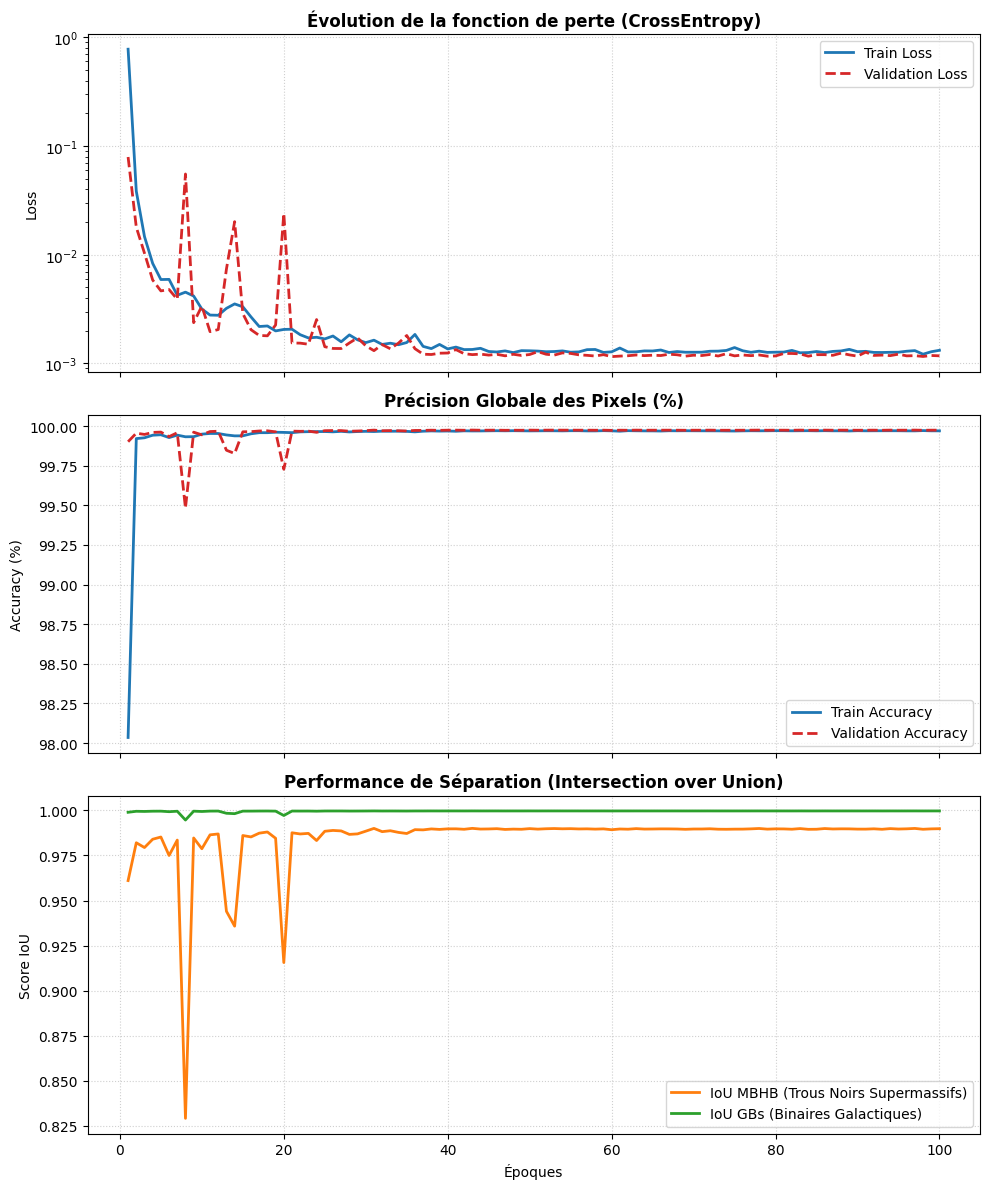

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement des métriques sauvegardées
df = pd.read_csv("C:\Stage LISA Mostafa\Serveur\Classification\metrics_history_classification.txt")

# 2. Création de la figure
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# Graphique 1 : Loss
ax1.plot(df['Epoch'], df['Train_Loss'], label='Train Loss', color='#1f77b4', linewidth=2)
ax1.plot(df['Epoch'], df['Val_Loss'], label='Validation Loss', color='#d62728', linestyle='--', linewidth=2)
ax1.set_title('Évolution de la fonction de perte (CrossEntropy)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Loss')
ax1.set_yscale('log') # Echelle log très recommandée car la loss baisse fort
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Graphique 2 : Accuracy
ax2.plot(df['Epoch'], df['Train_Acc'] * 100, label='Train Accuracy', color='#1f77b4', linewidth=2)
ax2.plot(df['Epoch'], df['Val_Acc'] * 100, label='Validation Accuracy', color='#d62728', linestyle='--', linewidth=2)
ax2.set_title('Précision Globale des Pixels (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

# Graphique 3 : IoU par type de source LISA
ax3.plot(df['Epoch'], df['Val_IoU_MBHB'], label='IoU MBHB (Trous Noirs Supermassifs)', color='#ff7f0e', linewidth=2)
ax3.plot(df['Epoch'], df['Val_IoU_GBs'], label='IoU GBs (Binaires Galactiques)', color='#2ca02c', linewidth=2)
ax3.set_title('Performance de Séparation (Intersection over Union)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Époques')
ax3.set_ylabel('Score IoU')
ax3.legend()
ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [3]:
from IPython.display import HTML, display
with open(r'C:\Stage LISA Mostafa\Serveur\Classification\train_lisa_model_classification.log', "r") as f:
    full_log = f.read()

display(HTML(f'''
<details style="border: 1px solid #ccc; padding: 10px; border-radius: 5px;">
    <summary style="cursor: pointer; fontweight: bold;"><b>Cliquez pour dérouler le journal d'entraînement complet (nohup.log)</b></summary>
    <pre style="max-height: 300px; overflow-y: scroll; background-color: #f8f9fa; padding: 10px; margin-top: 10px; font-size: 12px;">
{full_log}
    </pre>
</details>
'''))

Machine utilisée pour le test (Classification) : cuda

--- ÉVALUATION CLASSIFICATION : Classif_Test ---


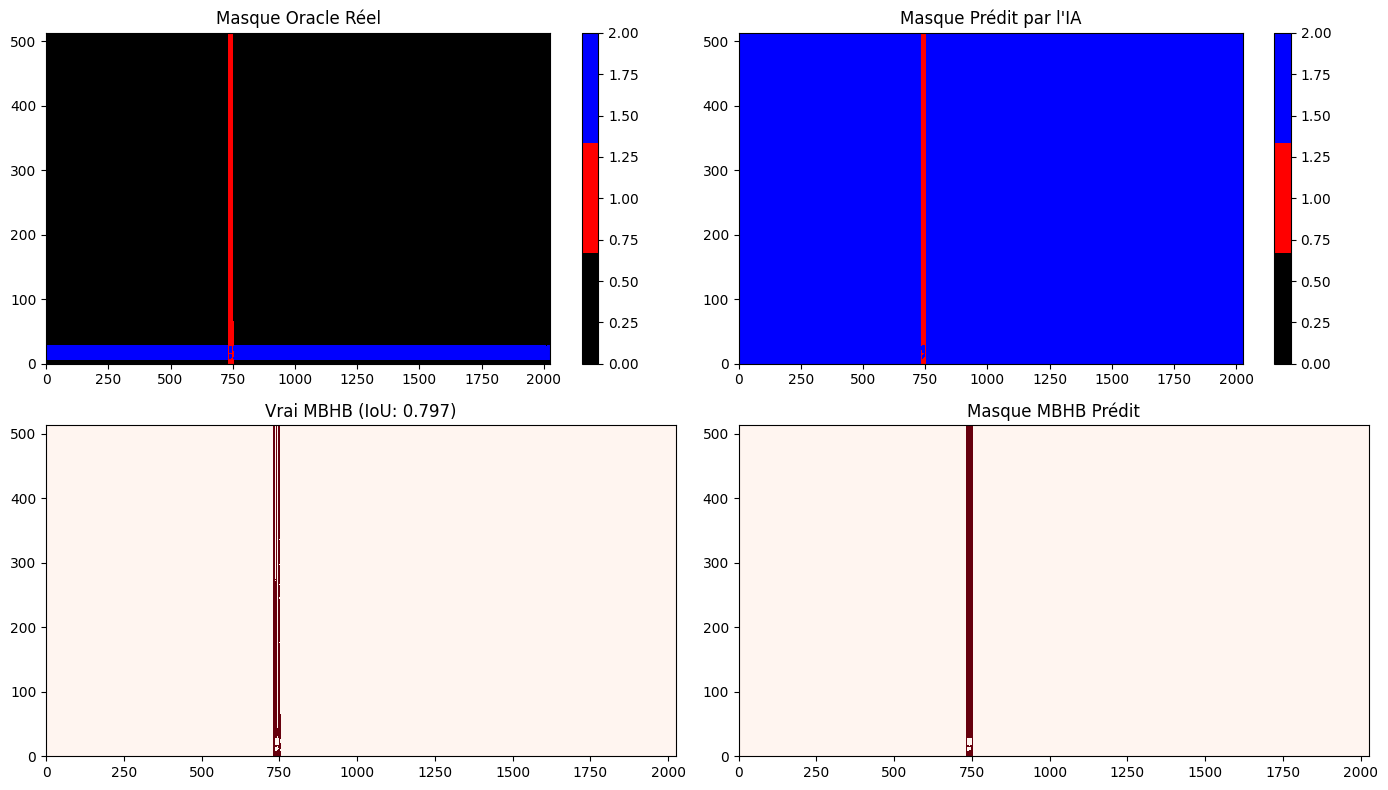

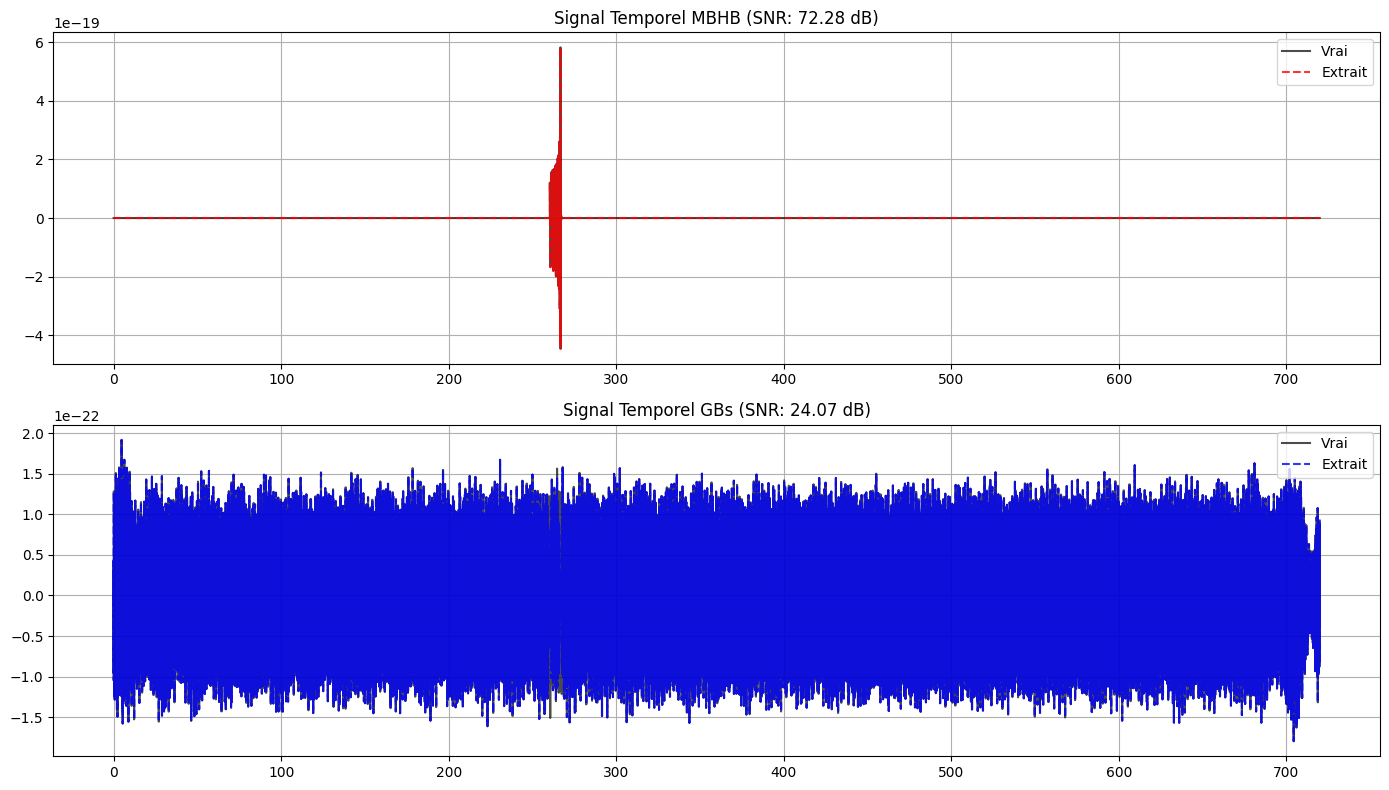

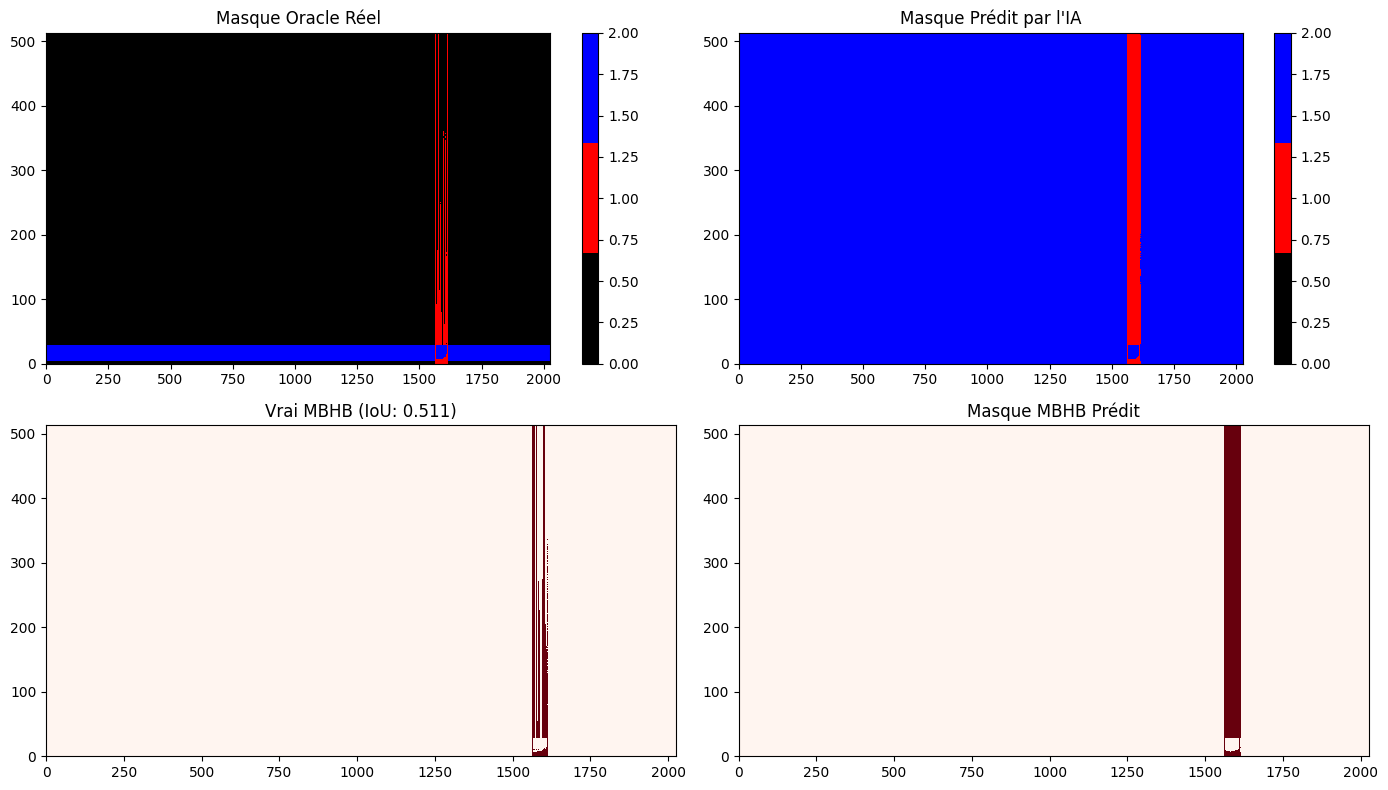

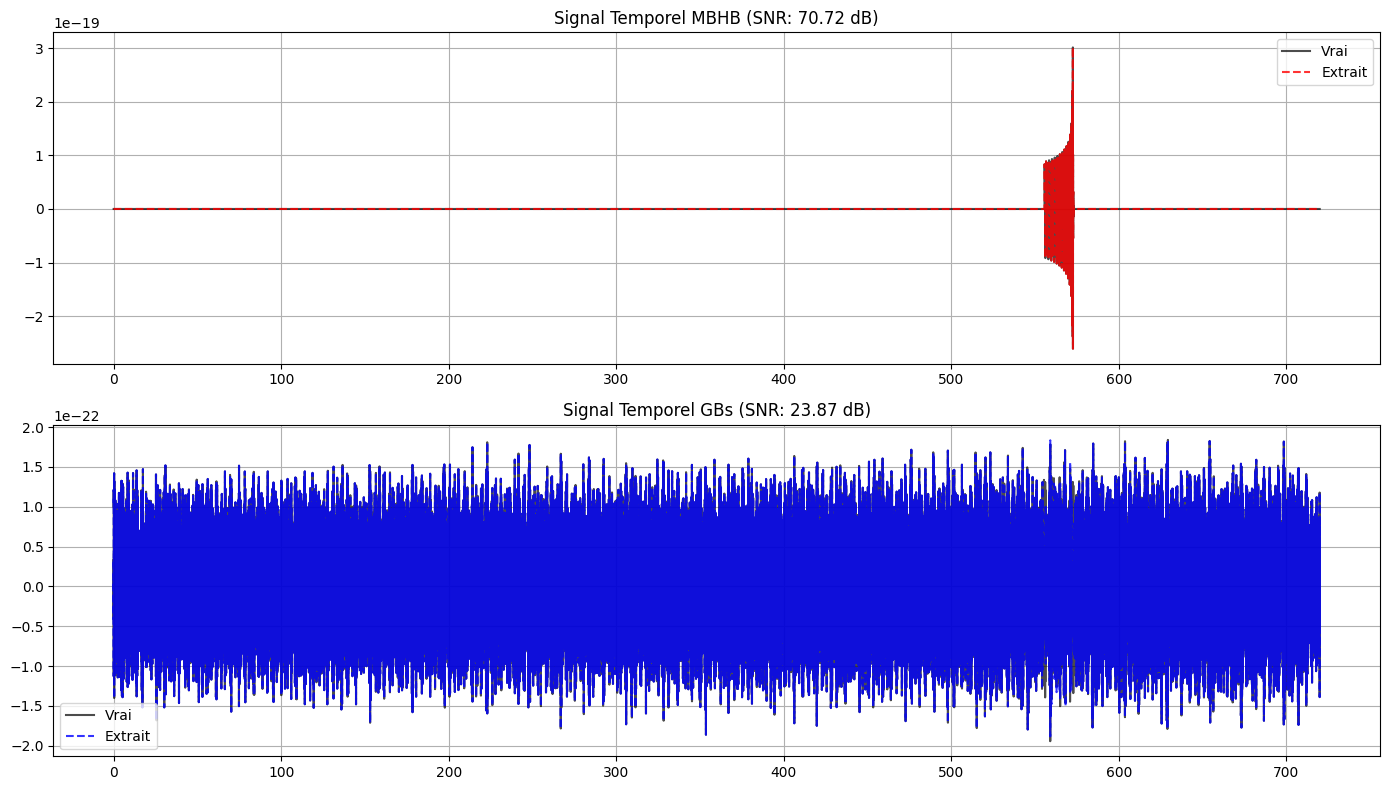

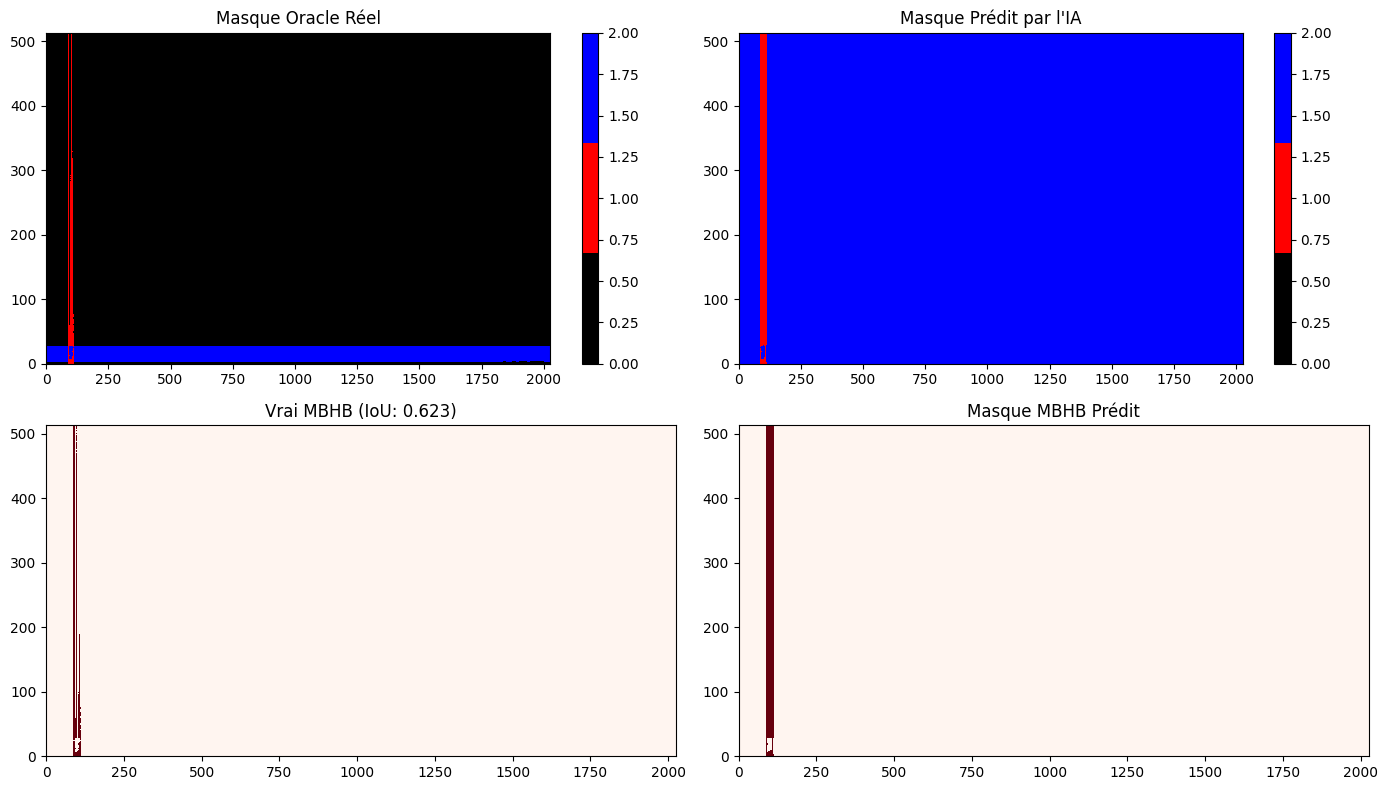

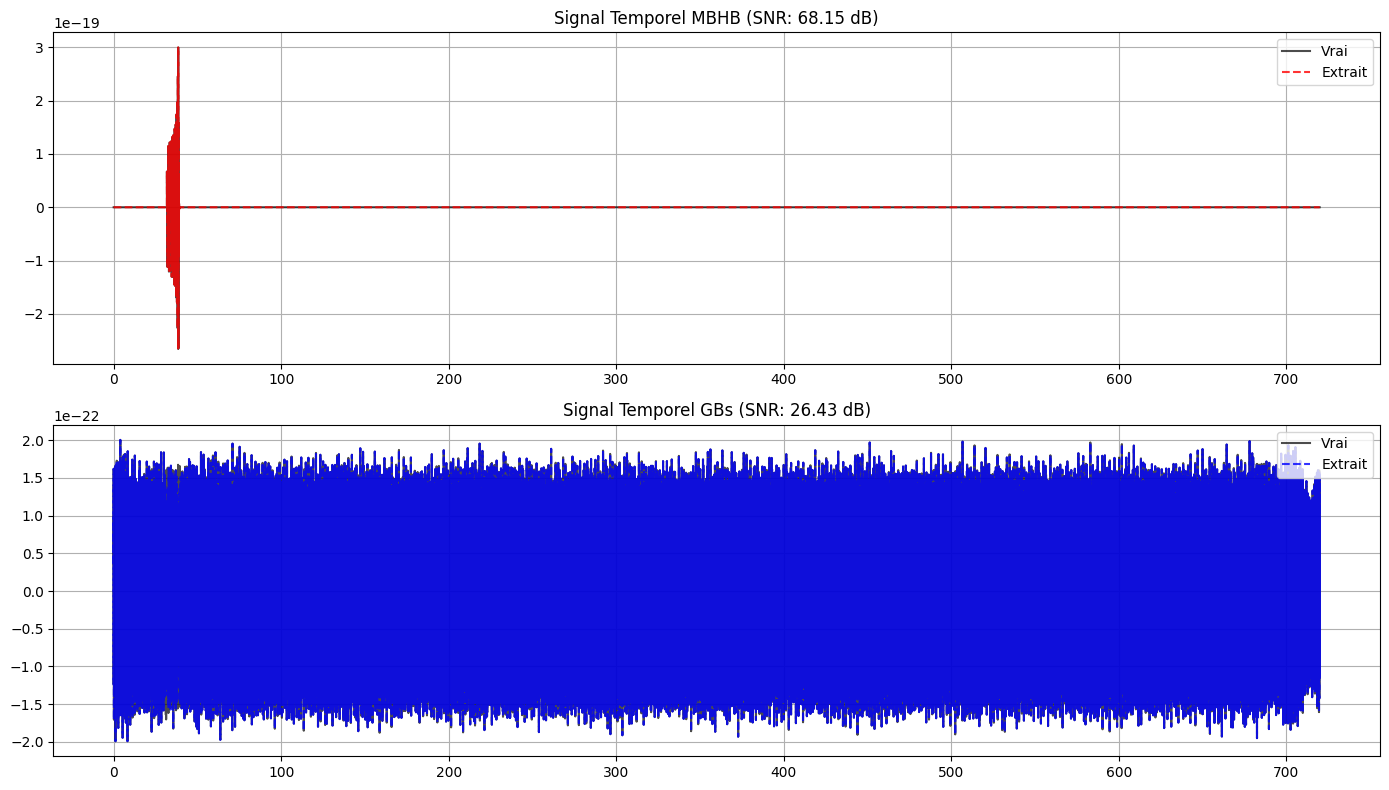


        RÉSULTATS MOYENS VALIDES CLASSIF : Classif_Test
Observations évaluées avec succès : 200
Précision GÉOMÉTRIQUE Moyenne (IoU) MBHB : 0.582
Précision GÉOMÉTRIQUE Moyenne (IoU) GBs  : 0.046
---------------------------------------------------------
Qualité PHYSIQUE Temporelle Moyenne MBHB : 72.13 dB
Qualité PHYSIQUE Temporelle Moyenne GBs  : 24.78 dB



In [4]:
%matplotlib inline
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import signal
import torch
import torch.nn as nn

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Machine utilisée pour le test (Classification) : {device}")

# Architecture réseau (chargement)
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNet(nn.Module):
    def __init__(self, num_classes=3):
        super(LISAUNet, self).__init__()
        self.inc = DoubleConv(1, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x = self.up1(x3)
        x = nn.functional.interpolate(x, size=x2.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = nn.functional.interpolate(x, size=x1.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up2(x)
        logits = self.outc(x)
        return nn.functional.interpolate(logits, size=orig_size, mode='bilinear', align_corners=True)

dt = 5.0
FS = 1.0 / dt
nfft = 1024
nperseg = nfft
noverlap = nfft - (nfft // 4)
win_type = 'blackmanharris'
eps_reg = 1e-45
noise_floor = 1e-26
cmap_classes = ListedColormap(['black', 'red', 'blue']) # 0=Fond, 1=MBHB, 2=GBs

def compute_iou_robust(true_mask, pred_mask):
    intersection = np.logical_and(true_mask, pred_mask).sum()
    union = np.logical_or(true_mask, pred_mask).sum()
    if union == 0: return None
    return intersection / union

def compute_snr_robust(true, est):
    numerator = np.sum(true**2)
    residual = true - est
    denominator = np.sum(residual**2)
    if numerator == 0: return None
    if denominator == 0: return 100.0
    ratio = numerator / denominator
    if ratio <= 0: return -40.0
    return 10 * np.log10(ratio)

def evaluer_dataset_classification(modele, chemin_h5, liste_indices, nom_experience):
    print(f"\n--- ÉVALUATION CLASSIFICATION : {nom_experience} ---")
    iou_mbhb_tot, iou_gbs_tot = [], []
    snr_mbhb_tot, snr_gbs_tot = [], []
    
    with h5py.File(chemin_h5, 'r') as f:
        for idx_boucle, k_test in enumerate(liste_indices):
            s1_true = f['target'][k_test, 0, :].astype(np.float64)
            s2_true = f['target'][k_test, 1, :].astype(np.float64)

            _, _, stft_s1 = signal.stft(s1_true, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, _, stft_s2 = signal.stft(s2_true, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            stft_mix = stft_s1 + stft_s2
            mag_mix = np.abs(stft_mix)

            mag_mbhb = np.abs(stft_s1)
            mag_gbs = np.abs(stft_s2)
            noise_channel = np.full_like(mag_mbhb, noise_floor)
            true_classes = np.argmax(np.stack([noise_channel, mag_mbhb, mag_gbs], axis=0), axis=0)

            true_mask_mbhb = (true_classes == 1).astype(np.float64)
            true_mask_gbs = (true_classes == 2).astype(np.float64)

            input_magnitude = np.log10(mag_mix + eps_reg)
            input_tensor = torch.tensor(input_magnitude, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

            with torch.no_grad():
                logits = modele(input_tensor)
                pred_classes = torch.argmax(logits, dim=1)[0].cpu().numpy()

            pred_mask_mbhb = (pred_classes == 1).astype(np.float64)
            pred_mask_gbs = (pred_classes == 2).astype(np.float64)

            stft_s1_est = stft_mix * pred_mask_mbhb
            stft_s2_est = stft_mix * pred_mask_gbs

            _, s1_est = signal.istft(stft_s1_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, s2_est = signal.istft(stft_s2_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)

            min_len = min(len(s1_true), len(s1_est))
            s1_t, s1_e = s1_true[:min_len], s1_est[:min_len]
            s2_t, s2_e = s2_true[:min_len], s2_est[:min_len]

            iou_m = compute_iou_robust(true_mask_mbhb, pred_mask_mbhb)
            iou_g = compute_iou_robust(true_mask_gbs, pred_mask_gbs)
            snr_m = compute_snr_robust(s1_t, s1_e)
            snr_g = compute_snr_robust(s2_t, s2_e)

            if iou_m is not None: iou_mbhb_tot.append(iou_m)
            if iou_g is not None: iou_gbs_tot.append(iou_g)
            if snr_m is not None: snr_mbhb_tot.append(snr_m)
            if snr_g is not None: snr_gbs_tot.append(snr_g)

            # Affichage des résultats pour les 3 premières itérations
            if idx_boucle < 3:
                fig, axs = plt.subplots(2, 2, figsize=(14, 8))
                im0 = axs[0, 0].pcolormesh(true_classes, cmap=cmap_classes, vmin=0, vmax=2)
                axs[0, 0].set_title('Masque Oracle Réel'); fig.colorbar(im0, ax=axs[0, 0])
                im1 = axs[0, 1].pcolormesh(pred_classes, cmap=cmap_classes, vmin=0, vmax=2)
                axs[0, 1].set_title('Masque Prédit par l\'IA'); fig.colorbar(im1, ax=axs[0, 1])
                
                title_m = f"Vrai MBHB (IoU: {iou_m:.3f})" if iou_m is not None else "MBHB Absents"
                axs[1, 0].pcolormesh(true_mask_mbhb, cmap='Reds'); axs[1, 0].set_title(title_m)
                axs[1, 1].pcolormesh(pred_mask_mbhb, cmap='Reds'); axs[1, 1].set_title('Masque MBHB Prédit')
                plt.tight_layout()
                plt.show()
                
                step = 1 if min_len < 50000 else 10
                time_axis = np.arange(min_len) * dt / 3600.0
                fig2, axs2 = plt.subplots(2, 1, figsize=(14, 8))
                axs2[0].plot(time_axis[::step], s1_t[::step], color='black', alpha=0.7, label='Vrai')
                axs2[0].plot(time_axis[::step], s1_e[::step], color='red', linestyle='--', alpha=0.8, label='Extrait')
                title_snr_m = f"Signal Temporel MBHB (SNR: {snr_m:.2f} dB)" if snr_m is not None else "Signal MBHB absent"
                axs2[0].set_title(title_snr_m); axs2[0].legend(); axs2[0].grid(True)
                
                axs2[1].plot(time_axis[::step], s2_t[::step], color='black', alpha=0.7, label='Vrai')
                axs2[1].plot(time_axis[::step], s2_e[::step], color='blue', linestyle='--', alpha=0.8, label='Extrait')
                title_snr_g = f"Signal Temporel GBs (SNR: {snr_g:.2f} dB)" if snr_g is not None else "Signal GBs absent"
                axs2[1].set_title(title_snr_g); axs2[1].legend(); axs2[1].grid(True)
                plt.tight_layout()
                plt.show()

    moy_iou_m = np.mean(iou_mbhb_tot) if iou_mbhb_tot else 0.0
    moy_iou_g = np.mean(iou_gbs_tot) if iou_gbs_tot else 0.0
    moy_snr_m = np.mean(snr_mbhb_tot) if snr_mbhb_tot else 0.0
    moy_snr_g = np.mean(snr_gbs_tot) if snr_gbs_tot else 0.0
    
    rapport = [
        f"\n=========================================================",
        f"        RÉSULTATS MOYENS VALIDES CLASSIF : {nom_experience}",
        f"=========================================================",
        f"Observations évaluées avec succès : {len(liste_indices)}",
        f"Précision GÉOMÉTRIQUE Moyenne (IoU) MBHB : {moy_iou_m:.3f}",
        f"Précision GÉOMÉTRIQUE Moyenne (IoU) GBs  : {moy_iou_g:.3f}",
        f"---------------------------------------------------------",
        f"Qualité PHYSIQUE Temporelle Moyenne MBHB : {moy_snr_m:.2f} dB",
        f"Qualité PHYSIQUE Temporelle Moyenne GBs  : {moy_snr_g:.2f} dB",
        f"=========================================================\n"
    ]
    for ligne in rapport: print(ligne)

if __name__ == "__main__":
    model = LISAUNet(num_classes=3).to(device)
    model.load_state_dict(torch.load(os.path.join(DATA_DIR, 'lisa_unet_2k_model_classification.pth'), map_location=device, weights_only=True))
    model.eval()

    h5_initial = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')
    indices_test = list(range(1800, 2000)) # Test limité à 5 pour l'affichage propre dans le notebook
    evaluer_dataset_classification(model, h5_initial, indices_test, "Classif_Test")


## Analyse :
Bien que cette méthode offre une base de référence (*baseline*) solide et facile à implémenter, elle présente une limite inhérente à la physique des signaux. Dans un spectrogramme réel, un pixel temps-fréquence contient souvent une superposition énergétique des signaux MBHB, des GBs et du bruit instrumental. L'attribution stricte à une seule classe entraîne inévitablement une perte d'information, car elle ignore la nature additive des ondes gravitationnelles.

---
## 2. Méthode 2 : Approche par Régression (Masques Souples)
Contrairement à la classification qui attribue un pixel à une source exclusive, la régression vise à prédire le **ratio de présence** de chaque signal (entre 0 et 1). Cette méthode est plus pertinente car elle modélise l'addition énergétique dans les zones de chevauchement spectral, ce qui évite d'ignorer complétement les signaux faibles situés sur les mêmes pixels que les signaux forts.


In [5]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from scipy import signal
from torch.utils.data import DataLoader, Dataset
import os

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"
h5_filename = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class LISADataset(Dataset):
    def __init__(self, h5_path, indices):
        self.h5_path = h5_path
        self.indices = indices
        self.dt = 5.0
        self.FS = 1.0 / self.dt
        self.nfft = 1024
        self.nperseg = self.nfft
        self.noverlap = self.nfft - (self.nfft // 4)
        self.win_type = 'blackmanharris'
        self.eps_reg = 1e-45

    def __len__(self): return len(self.indices)

    def __getitem__(self, idx):
        real_k = self.indices[idx]
        with h5py.File(self.h5_path, 'r') as f:
            s1_true = f['target'][real_k, 0, :].astype(np.float64)
            s2_true = f['target'][real_k, 1, :].astype(np.float64)

        _, _, stft_s1 = signal.stft(s1_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        _, _, stft_s2 = signal.stft(s2_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        stft_mix = stft_s1 + stft_s2

        mag_mix = np.abs(stft_mix)
        mask_mbhb = np.abs(stft_s1) / (np.abs(stft_s2) + mag_mix + self.eps_reg)
        mask_gbs = np.abs(stft_s2) / (np.abs(stft_s1) + mag_mix + self.eps_reg)

        X = np.expand_dims(np.log10(mag_mix + self.eps_reg), axis=0)
        Y = np.concatenate([np.expand_dims(mask_mbhb, axis=0), np.expand_dims(mask_gbs, axis=0)], axis=0)
        return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNet(nn.Module):
    def __init__(self):
        super(LISAUNet, self).__init__()
        self.inc = DoubleConv(1, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, 2, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x = self.up1(x3)
        x = nn.functional.interpolate(x, size=x2.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = nn.functional.interpolate(x, size=x1.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up2(x)
        logits = self.outc(x)
        logits = nn.functional.interpolate(logits, size=orig_size, mode='bilinear', align_corners=True)
        return self.sigmoid(logits)

class LISAAdaptiveLoss(nn.Module):
    def __init__(self, weight_gbs=8.0):
        super(LISAAdaptiveLoss, self).__init__()
        self.weight_gbs = weight_gbs
        self.base_loss = nn.MSELoss(reduction='none')

    def forward(self, pred, target):
        loss_pixel = self.base_loss(pred, target)
        weight_matrix = torch.ones_like(target)
        weight_matrix[:, 1:2, :, :] = self.weight_gbs 
        return torch.mean(loss_pixel * weight_matrix)

LANCER_ENTRAINEMENT = False

if LANCER_ENTRAINEMENT:
    all_indices = list(range(2000))
    train_indices = all_indices[:1600]
    val_indices = all_indices[1600:1800]
    train_loader = DataLoader(LISADataset(h5_filename, train_indices), batch_size=8, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(LISADataset(h5_filename, val_indices), batch_size=8, shuffle=False, num_workers=4, pin_memory=True)
    model = LISAUNet().to(device)
    criterion = LISAAdaptiveLoss(weight_gbs=8.0)
    optimizer = optim.Adam(model.parameters(), lr=0.0002)
    print("Lancement de l'apprentissage sécurisé...")
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for batch_X, batch_Y in train_loader:
            batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_X), batch_Y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch_X.size(0)
        train_loss /= len(train_loader.dataset)
        train_loss_history.append(train_loss)
    
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_X, batch_Y in val_loader:
                batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
                val_loss += criterion(model(batch_X), batch_Y).item() * batch_X.size(0)
        val_loss /= len(val_loader.dataset)
        val_loss_history.append(val_loss)
    
        print(f"Époque [{epoch+1}/{num_epochs}] -> Train Loss : {train_loss:.6f} | Val Loss : {val_loss:.6f}")
    
        # --- SÉCURITÉ : SAUVEGARDE DU MEILLEUR MODÈLE UNIQUEMENT ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'lisa_unet_2k_model_regression.pth')
            print(f"   => Nouveau record de Validation ! Modèle sauvegardé à l'époque {epoch+1}")
else:
    print("Entraînement de régression ignoré, passage à l'évaluation direct.")


Entraînement de régression ignoré, passage à l'évaluation direct.


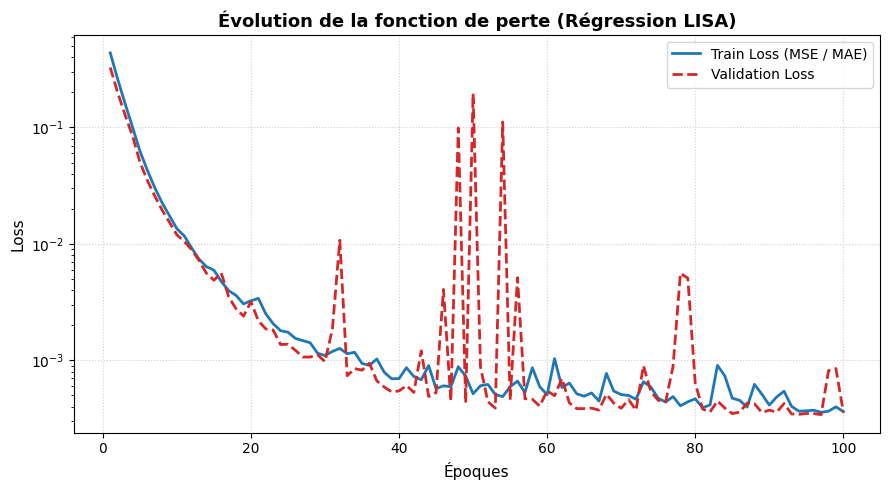

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement des métriques sauvegardées (avec 'r' pour éviter l'erreur de chemin Windows)
df = pd.read_csv(r"C:\Stage LISA Mostafa\Serveur\Regression\loss_history_regression.txt")

# 2. Création de la figure (un seul graphique dédié à la régression)
plt.figure(figsize=(9, 5))

# Tracé des courbes de loss
plt.plot(df['Epoch'], df['Train_Loss'], label='Train Loss (MSE / MAE)', color='#1f77b4', linewidth=2)
plt.plot(df['Epoch'], df['Validation_Loss'], label='Validation Loss', color='#d62728', linestyle='--', linewidth=2)

# Configuration du graphique
plt.title('Évolution de la fonction de perte (Régression LISA)', fontsize=13, fontweight='bold')
plt.xlabel('Époques', fontsize=11)
plt.ylabel('Loss', fontsize=11)

# Échelle logarithmique (essentielle pour voir la convergence des signaux)
plt.yscale('log')

plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Affichage
plt.show()

In [7]:
from IPython.display import HTML, display
with open(r"C:\Stage LISA Mostafa\Serveur\Regression\train_lisa_2k_weighted_regression.log", "r") as f:
    full_log = f.read()

display(HTML(f'''
<details style="border: 1px solid #ccc; padding: 10px; border-radius: 5px;">
    <summary style="cursor: pointer; fontweight: bold;"><b>Cliquez pour dérouler le journal d'entraînement complet (nohup.log)</b></summary>
    <pre style="max-height: 300px; overflow-y: scroll; background-color: #f8f9fa; padding: 10px; margin-top: 10px; font-size: 12px;">
{full_log}
    </pre>
</details>
'''))


--- ÉVALUATION REGRESSION : Regress_Test ---


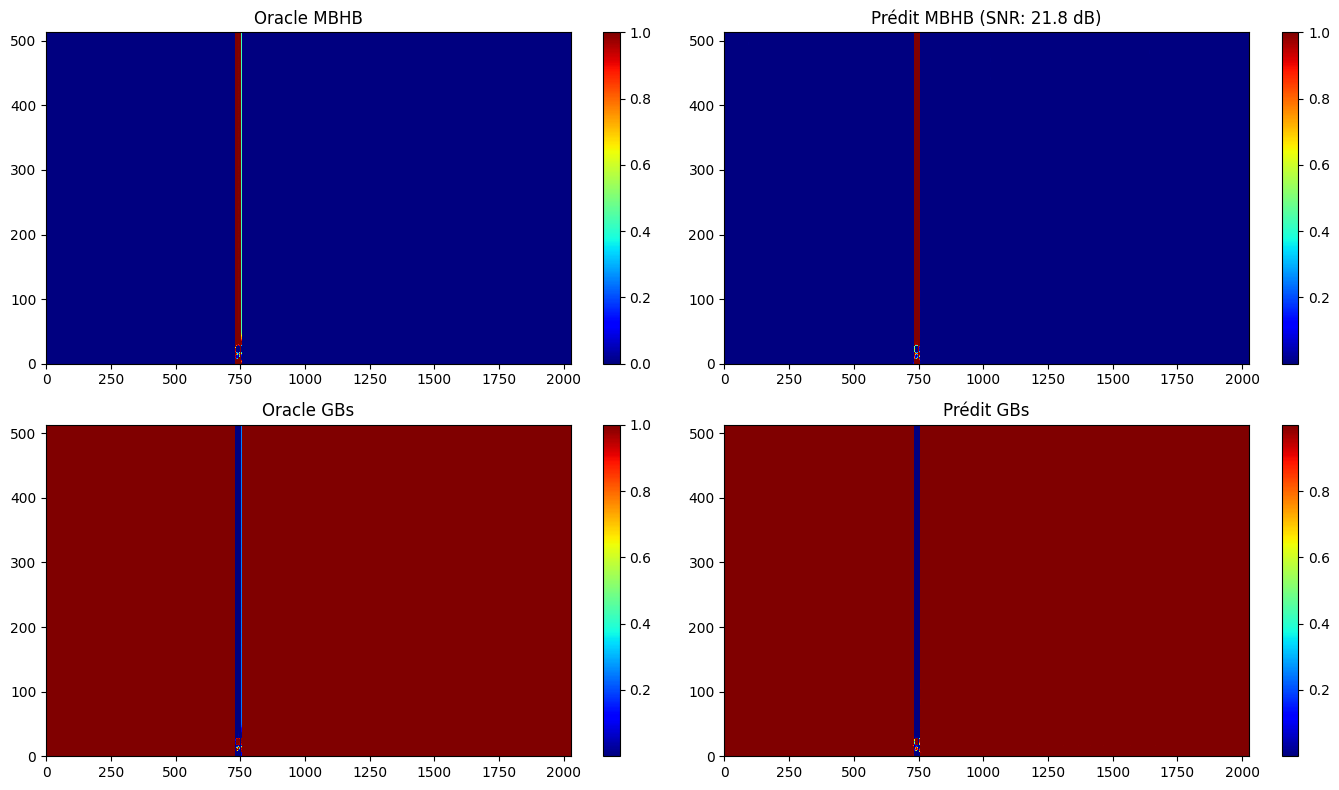

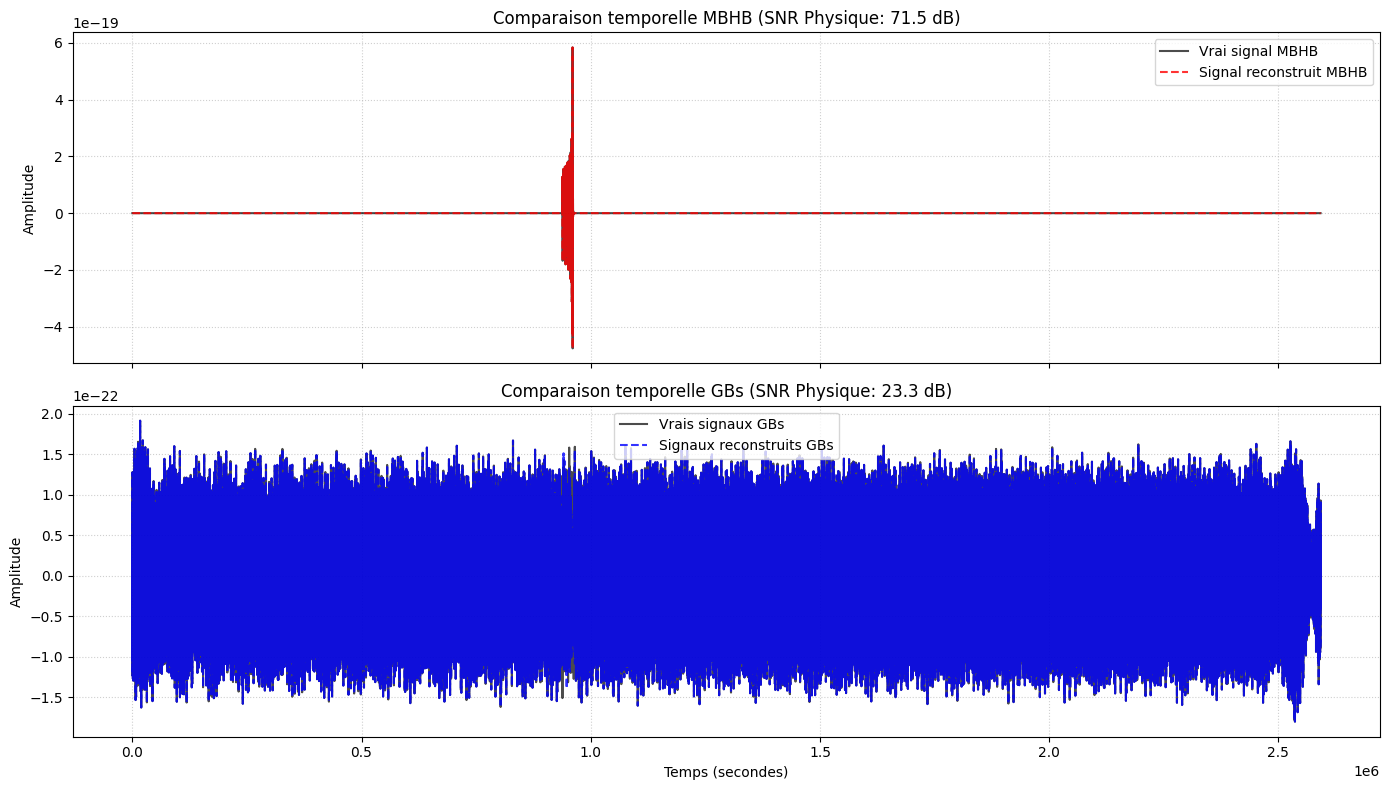

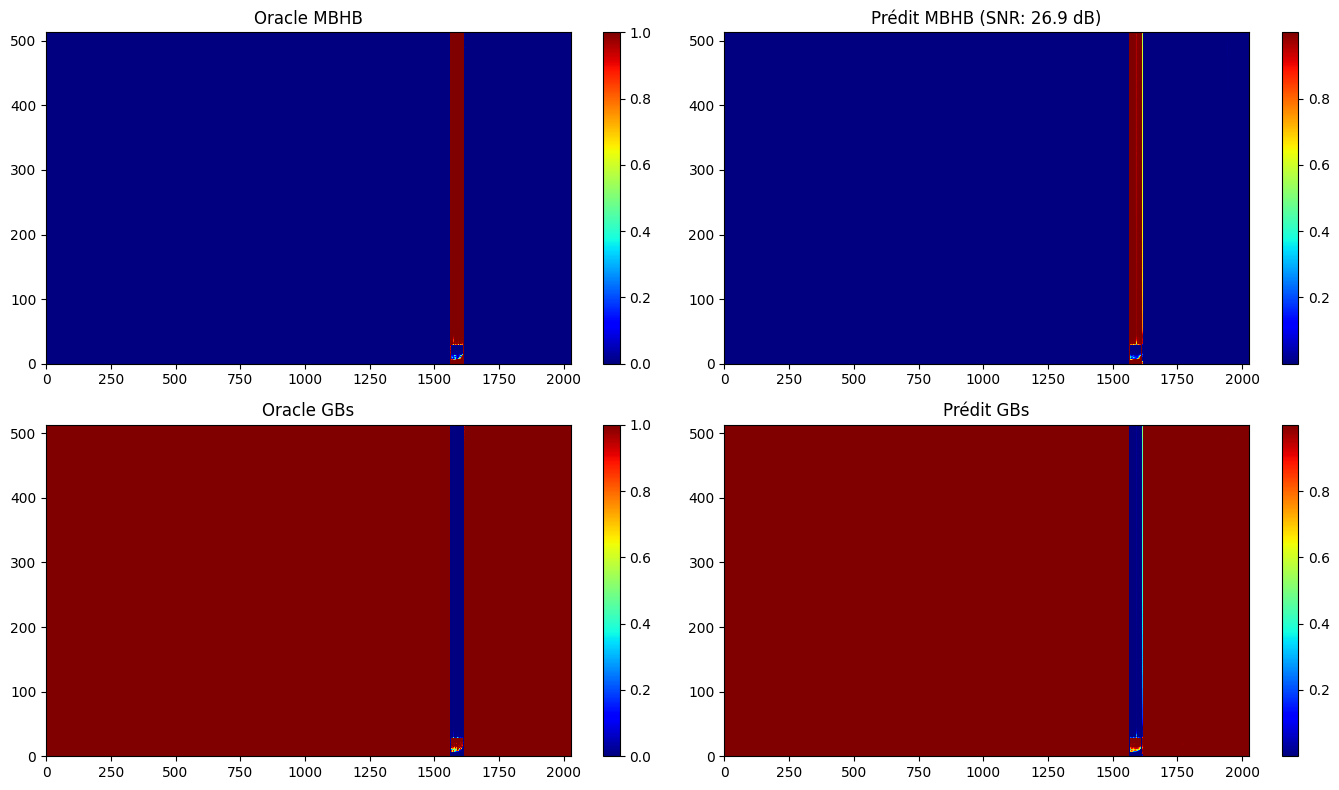

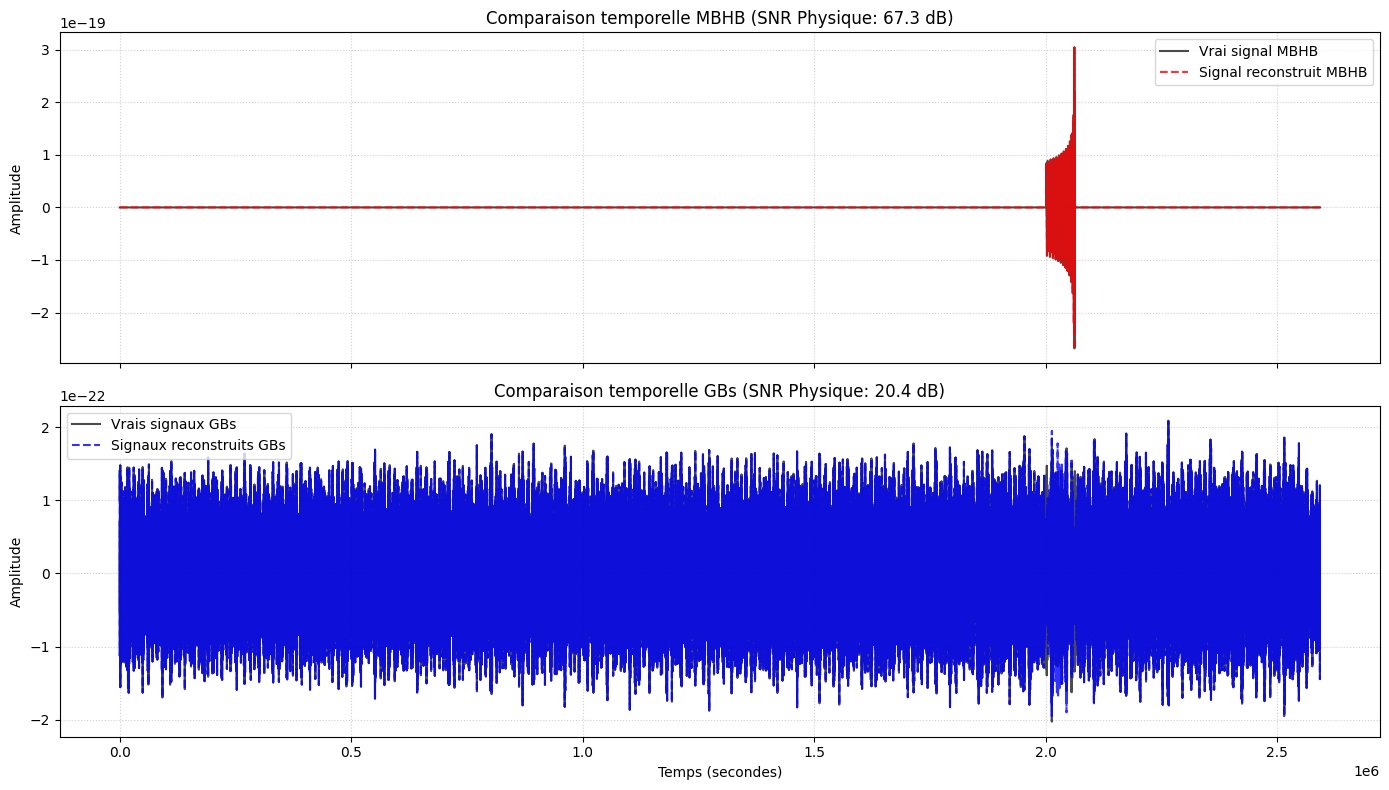

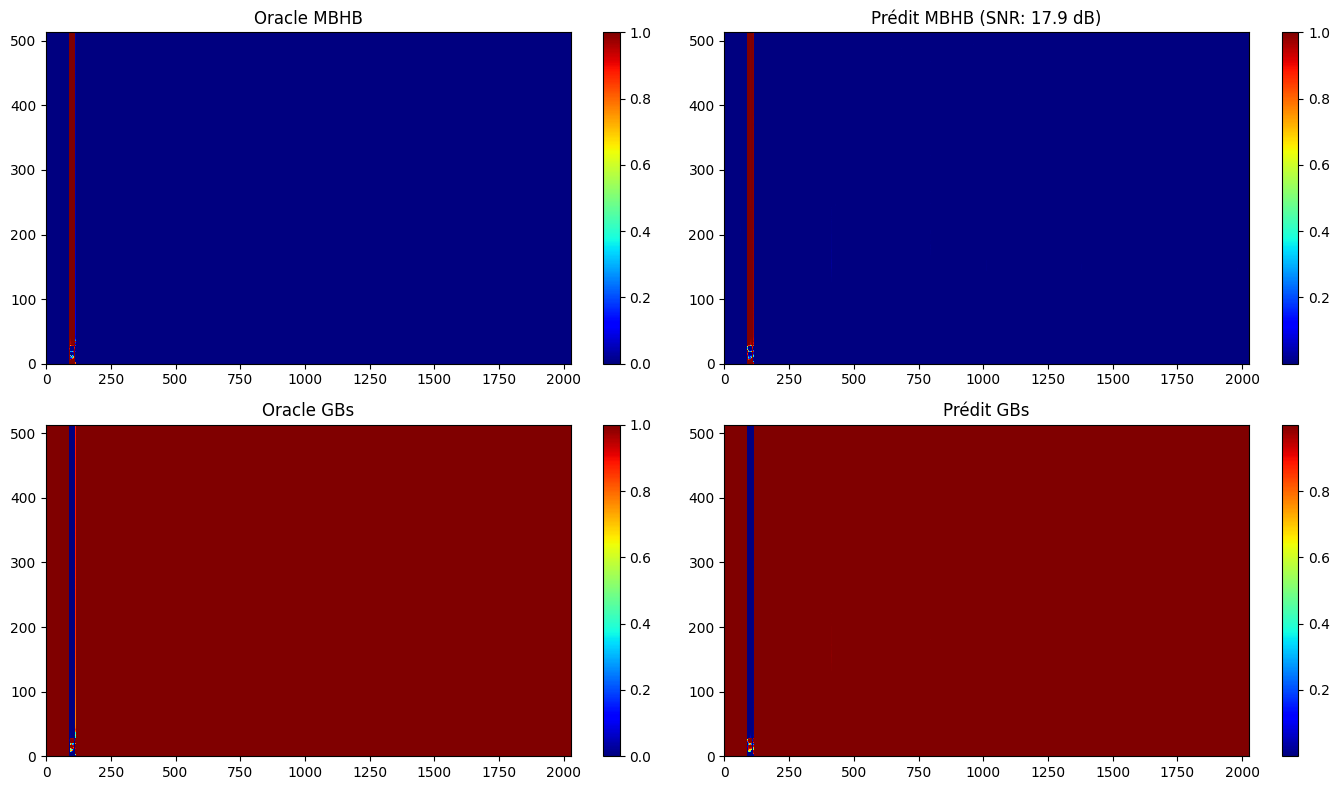

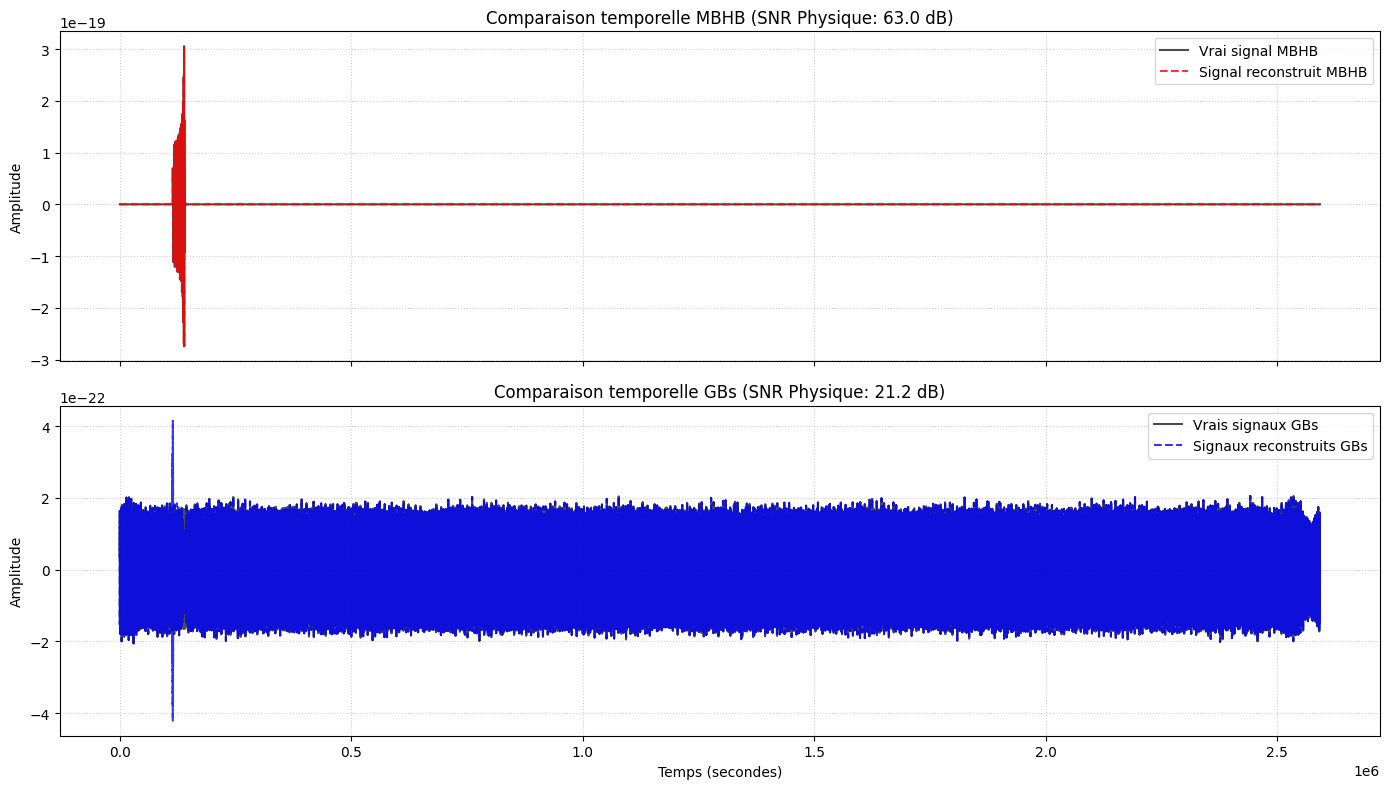


        RÉSULTATS MOYENS VALIDES : Regress_Test
SNR GÉOMÉTRIQUE Moyen (Masque MBHB) : 24.22 dB
SNR GÉOMÉTRIQUE Moyen (Masque GBs)  : 42.74 dB
---------------------------------------------------------
SNR PHYSIQUE Temporel Moyen MBHB    : 67.65 dB
SNR PHYSIQUE Temporel Moyen GBs     : 20.29 dB



In [8]:
%matplotlib inline
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy import signal
import torch
import torch.nn as nn

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Chargement classes du Modèle...
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNet(nn.Module):
    def __init__(self):
        super(LISAUNet, self).__init__()
        self.inc = DoubleConv(1, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, 2, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x = self.up1(x3)
        x = nn.functional.interpolate(x, size=x2.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = nn.functional.interpolate(x, size=x1.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up2(x)
        logits = self.outc(x)
        logits = nn.functional.interpolate(logits, size=orig_size, mode='bilinear', align_corners=True)
        return self.sigmoid(logits)

dt = 5.0
FS = 1.0 / dt
nfft = 1024
nperseg = nfft
noverlap = nfft - (nfft // 4)
win_type = 'blackmanharris'
eps_reg = 1e-45

def compute_snr_robust(true, est):
    numerator = np.sum(true**2)
    residual = true - est
    denominator = np.sum(residual**2)
    if numerator == 0: return None
    if denominator == 0: return 100.0
    ratio = numerator / denominator
    if ratio <= 0: return -40.0
    return 10 * np.log10(ratio)

def evaluer_dataset_regression(modele, chemin_h5, liste_indices, nom_experience):
    print(f"\n--- ÉVALUATION REGRESSION : {nom_experience} ---")
    snr_mask_mbhb_tot, snr_mask_gbs_tot = [], []
    snr_sig_mbhb_tot, snr_sig_gbs_tot = [], []
    
    with h5py.File(chemin_h5, 'r') as f:
        for idx_boucle, k_test in enumerate(liste_indices):
            s1_true = f['target'][k_test, 0, :].astype(np.float64)
            s2_true = f['target'][k_test, 1, :].astype(np.float64)

            _, _, stft_s1 = signal.stft(s1_true, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, _, stft_s2 = signal.stft(s2_true, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            stft_mix = stft_s1 + stft_s2
            mag_mix = np.abs(stft_mix)

            true_mask_mbhb = np.abs(stft_s1) / (np.abs(stft_s2) + mag_mix + eps_reg)
            true_mask_gbs = np.abs(stft_s2) / (np.abs(stft_s1) + mag_mix + eps_reg)

            input_magnitude = np.log10(mag_mix + eps_reg)
            input_tensor = torch.tensor(input_magnitude, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

            with torch.no_grad():
                predictions = modele(input_tensor)
                pred_mask_mbhb = predictions[0, 0].cpu().numpy()
                pred_mask_gbs = predictions[0, 1].cpu().numpy()

            mask_gbs_final = np.where(pred_mask_mbhb > 0.8, 1.0 - pred_mask_mbhb, pred_mask_gbs)

            stft_s1_est = stft_mix * pred_mask_mbhb
            stft_s2_est = stft_mix * mask_gbs_final

            _, s1_est = signal.istft(stft_s1_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, s2_est = signal.istft(stft_s2_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)

            min_len = min(len(s1_true), len(s1_est))
            s1_t, s1_e = s1_true[:min_len], s1_est[:min_len]
            s2_t, s2_e = s2_true[:min_len], s2_est[:min_len]

            snr_m_mask = compute_snr_robust(true_mask_mbhb, pred_mask_mbhb)
            snr_g_mask = compute_snr_robust(true_mask_gbs, pred_mask_gbs)
            snr_m_sig = compute_snr_robust(s1_t, s1_e)
            snr_g_sig = compute_snr_robust(s2_t, s2_e)

            if snr_m_mask is not None: snr_mask_mbhb_tot.append(snr_m_mask)
            if snr_g_mask is not None: snr_mask_gbs_tot.append(snr_g_mask)
            if snr_m_sig is not None: snr_sig_mbhb_tot.append(snr_m_sig)
            if snr_g_sig is not None: snr_sig_gbs_tot.append(snr_g_sig)

            if idx_boucle < 3:
                fig, axs = plt.subplots(2, 2, figsize=(14, 8))
                t_m_m = np.clip(true_mask_mbhb, 0, 1)
                p_m_m = np.clip(pred_mask_mbhb, 0, 1)
                
                im0 = axs[0, 0].pcolormesh(t_m_m, cmap='jet'); axs[0, 0].set_title('Oracle MBHB'); fig.colorbar(im0, ax=axs[0, 0])
                title_pred = f"Prédit MBHB (SNR: {snr_m_mask:.1f} dB)" if snr_m_mask is not None else "Prédit MBHB (Absent)"
                im1 = axs[0, 1].pcolormesh(p_m_m, cmap='jet'); axs[0, 1].set_title(title_pred); fig.colorbar(im1, ax=axs[0, 1])
                
                im2 = axs[1, 0].pcolormesh(np.clip(true_mask_gbs, 0, 1), cmap='jet'); axs[1, 0].set_title('Oracle GBs'); fig.colorbar(im2, ax=axs[1, 0])
                im3 = axs[1, 1].pcolormesh(np.clip(pred_mask_gbs, 0, 1), cmap='jet'); axs[1, 1].set_title('Prédit GBs'); fig.colorbar(im3, ax=axs[1, 1])
                
                plt.tight_layout()
                plt.show()


                time_axis = np.arange(len(s1_t)) * dt

                fig2, axs2 = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
                
                # Affichage du signal MBHB (S1)
                axs2[0].plot(time_axis, s1_t, label='Vrai signal MBHB', color='black', alpha=0.7)
                axs2[0].plot(time_axis, s1_e, label='Signal reconstruit MBHB', color='red', linestyle='--', alpha=0.8)
                title_mbhb = f'Comparaison temporelle MBHB (SNR Physique: {snr_m_sig:.1f} dB)' if snr_m_sig is not None else 'Comparaison temporelle MBHB'
                axs2[0].set_title(title_mbhb)
                axs2[0].set_ylabel('Amplitude')
                axs2[0].legend()
                axs2[0].grid(True, linestyle=':', alpha=0.6)

                # Affichage du signal GBs (S2)
                axs2[1].plot(time_axis, s2_t, label='Vrais signaux GBs', color='black', alpha=0.7)
                axs2[1].plot(time_axis, s2_e, label='Signaux reconstruits GBs', color='blue', linestyle='--', alpha=0.8)
                title_gbs = f'Comparaison temporelle GBs (SNR Physique: {snr_g_sig:.1f} dB)' if snr_g_sig is not None else 'Comparaison temporelle GBs'
                axs2[1].set_title(title_gbs)
                axs2[1].set_xlabel('Temps (secondes)')
                axs2[1].set_ylabel('Amplitude')
                axs2[1].legend()
                axs2[1].grid(True, linestyle=':', alpha=0.6)

                plt.tight_layout()
                plt.show()

    moy_mask_m = np.mean(snr_mask_mbhb_tot) if snr_mask_mbhb_tot else 0.0
    moy_mask_g = np.mean(snr_mask_gbs_tot) if snr_mask_gbs_tot else 0.0
    moy_sig_m = np.mean(snr_sig_mbhb_tot) if snr_sig_mbhb_tot else 0.0
    moy_sig_g = np.mean(snr_sig_gbs_tot) if snr_sig_gbs_tot else 0.0
    
    rapport = [
        f"\n=========================================================",
        f"        RÉSULTATS MOYENS VALIDES : {nom_experience}",
        f"=========================================================",
        f"SNR GÉOMÉTRIQUE Moyen (Masque MBHB) : {moy_mask_m:.2f} dB",
        f"SNR GÉOMÉTRIQUE Moyen (Masque GBs)  : {moy_mask_g:.2f} dB",
        f"---------------------------------------------------------",
        f"SNR PHYSIQUE Temporel Moyen MBHB    : {moy_sig_m:.2f} dB",
        f"SNR PHYSIQUE Temporel Moyen GBs     : {moy_sig_g:.2f} dB",
        f"=========================================================\n"
    ]
    for ligne in rapport: print(ligne)

if __name__ == "__main__":
    model = LISAUNet().to(device)
    model.load_state_dict(torch.load(os.path.join(DATA_DIR, 'lisa_unet_2k_model_regression.pth'), map_location=device, weights_only=True))
    model.eval()

    h5_initial = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')
    indices_test = list(range(1800, 2000))
    evaluer_dataset_regression(model, h5_initial, indices_test, "Regress_Test")


## Analyse : 
En générant un masque continu, le modèle U-Net quantifie la proportion d'énergie appartenant à chaque source dans un même pixel. Cela permet une séparation beaucoup plus fine lors des chevauchements de signaux. Cependant, cette méthode n'opère généralement que sur l'amplitude du spectrogramme. L'information de la phase d'origine du signal est donc ignorée, ce qui limite la fidélité de la reconstruction temporelle de l'onde.

---
## 3. Méthode 3 : Les Masques Complexes (Filtrage inverse direct)
C'est la méthode de traitement du signal la plus avancée. Le réseau neuronal ne prend pas seulement le module en entrée, mais décompose la matrice complexe (Partie Réelle, Partie Imaginaire). Le réseau de neurones U-Net génère ensuite un filtre complexe qui multiplie le signal mélangé d'origine. Cette technique garantit que l'algorithme modifie l'amplitude **et corrige la phase** de l'onde extraite.

*Trois modèles sont disponibles dans le dossier Data pour cette méthode : `mse`, `mae`, et `both` (combinaison). Par défaut le script de test ci-dessous chargera le modèle optimisé sur le MSE.*


In [9]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from scipy import signal
from torch.utils.data import DataLoader, Dataset
import os

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"
h5_filename = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class LISADatasetComplexe(Dataset):
    def __init__(self, h5_path, indices, scale_factor=1e21):
        self.h5_path = h5_path
        self.indices = indices
        self.scale_factor = scale_factor
        self.dt = 5.0
        self.FS = 1.0 / self.dt
        self.nfft = 1024
        self.nperseg = self.nfft
        self.noverlap = self.nfft - (self.nfft // 4)
        self.win_type = 'blackmanharris'

    def __len__(self): return len(self.indices)

    def __getitem__(self, idx):
        real_k = self.indices[idx]
        with h5py.File(self.h5_path, 'r') as f:
            s1_true = f['target'][real_k, 0, :].astype(np.float64) * self.scale_factor
            s2_true = f['target'][real_k, 1, :].astype(np.float64) * self.scale_factor

        _, _, stft_s1 = signal.stft(s1_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        _, _, stft_s2 = signal.stft(s2_true, fs=self.FS, window=self.win_type, nperseg=self.nperseg, noverlap=self.noverlap, nfft=self.nfft)
        stft_mix = stft_s1 + stft_s2

        X = np.stack([np.real(stft_mix), np.imag(stft_mix)], axis=0)
        Y = np.stack([np.real(stft_s1), np.imag(stft_s1), np.real(stft_s2), np.imag(stft_s2)], axis=0)

        return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNetComplexFilter(nn.Module):
    def __init__(self):
        super(LISAUNetComplexFilter, self).__init__()
        self.inc = DoubleConv(2, 16) 
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, 4, kernel_size=1)
        # Pas de sigmoid ici, permet le dephasage complet !

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        up = self.up1(x3)
        up = nn.functional.interpolate(up, size=x2.shape[2:], mode='bilinear', align_corners=True)
        up = torch.cat([up, x2], dim=1)
        up = self.conv_up1(up)
        up = self.up2(up)
        up = nn.functional.interpolate(up, size=x1.shape[2:], mode='bilinear', align_corners=True)
        up = torch.cat([up, x1], dim=1)
        up = self.conv_up2(up)
        H = self.outc(up)
        H = nn.functional.interpolate(H, size=orig_size, mode='bilinear', align_corners=True)

        X_R = x[:, 0:1, :, :]
        X_I = x[:, 1:2, :, :]
        H_R_MBHB, H_I_MBHB = H[:, 0:1, :, :], H[:, 1:2, :, :]
        H_R_GB, H_I_GB   = H[:, 2:3, :, :], H[:, 3:4, :, :]

        S_R_MBHB = (H_R_MBHB * X_R) - (H_I_MBHB * X_I)
        S_I_MBHB = (H_R_MBHB * X_I) + (H_I_MBHB * X_R)
        S_R_GB = (H_R_GB * X_R) - (H_I_GB * X_I)
        S_I_GB = (H_R_GB * X_I) + (H_I_GB * X_R)

        return torch.cat([S_R_MBHB, S_I_MBHB, S_R_GB, S_I_GB], dim=1)

class ComplexLoss(nn.Module):
    def __init__(self, mode='both'):
        super(ComplexLoss, self).__init__()
        self.mode = mode.lower()
        self.mse = nn.MSELoss()
        self.mae = nn.L1Loss()

    def forward(self, pred, target):
        if self.mode == 'mse': return self.mse(pred, target)
        elif self.mode == 'mae': return self.mae(pred, target)
        elif self.mode == 'both': return self.mse(pred, target) + self.mae(pred, target)

# --- EXECUTION ENTRAINEMENT (DESACTIVEE) ---
LANCER_ENTRAINEMENT = False

if LANCER_ENTRAINEMENT:
    all_indices = list(range(2000))
    train_indices = all_indices[:1600]
    val_indices = all_indices[1600:1800]
    train_loader = DataLoader(LISADatasetComplexe(h5_filename, train_indices), batch_size=6, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(LISADatasetComplexe(h5_filename, val_indices), batch_size=6, shuffle=False, num_workers=4, pin_memory=True)
    model = LISAUNetComplexFilter().to(device)
    
    LOSS_MODE = 'mse' # Remplacer par 'mae' ou 'both'
    criterion = ComplexLoss(mode=LOSS_MODE).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0005)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

    num_epochs = 100
    best_val_loss = float('inf')

    train_loss_history = []
    val_loss_history = []

    print(f"Lancement de l'apprentissage complexe (Loss: {LOSS_MODE.upper()})...")

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for batch_X, batch_Y in train_loader:
            batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)

            optimizer.zero_grad()
            preds = model(batch_X)
            loss = criterion(preds, batch_Y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * batch_X.size(0)

        train_loss /= len(train_loader.dataset)
        train_loss_history.append(train_loss)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_X, batch_Y in val_loader:
                batch_X, batch_Y = batch_X.to(device), batch_Y.to(device)
                preds = model(batch_X)
                val_loss += criterion(preds, batch_Y).item() * batch_X.size(0)

        val_loss /= len(val_loader.dataset)
        val_loss_history.append(val_loss)

        # Step du scheduler pour baisser le LR si on stagne
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]['lr']
        print(f"Ép [{epoch+1}/{num_epochs}] -> LR: {current_lr:.6f} | Train Loss : {train_loss:.4f} | Val Loss : {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'lisa_unet_complexe_{LOSS_MODE}.pth')
            print(f"   => Nouveau record ! Modèle sauvegardé.")
else:
    print("Modèles complexes déjà entraînés. Passez directement au bloc de test.")


Modèles complexes déjà entraînés. Passez directement au bloc de test.


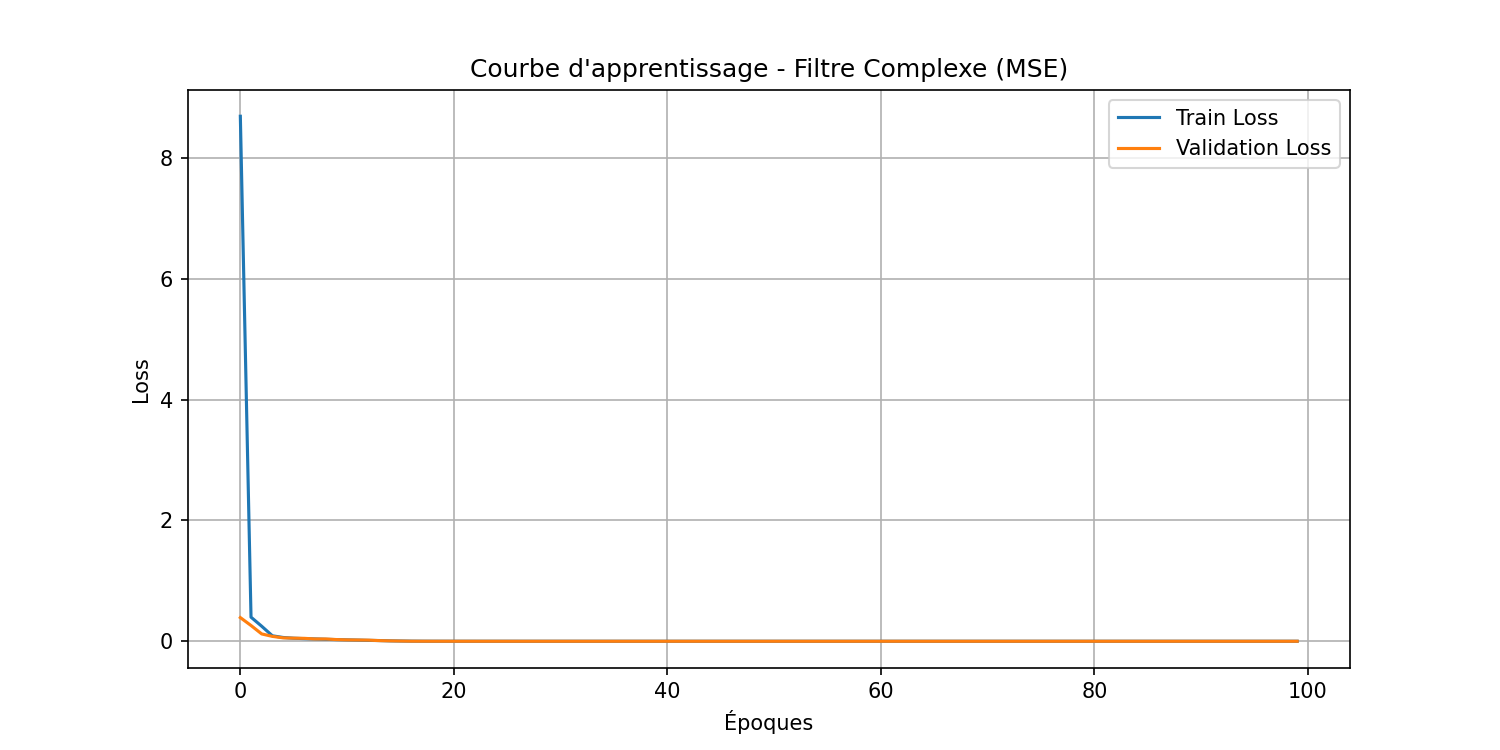

In [10]:
from IPython.display import Image, display

# Affichage direct de la figure 300 DPI sauvegardée
display(Image(filename="C:\Stage LISA Mostafa\Serveur\Masques Complexe\MSE\courbes_complexe_mse.png", width=800))

In [11]:
from IPython.display import HTML, display
with open(r"C:\Stage LISA Mostafa\Serveur\Masques Complexe\MSE\Train_LISA_MSE.log", "r") as f:
    full_log = f.read()

display(HTML(f'''
<details style="border: 1px solid #ccc; padding: 10px; border-radius: 5px;">
    <summary style="cursor: pointer; fontweight: bold;"><b>Cliquez pour dérouler le journal d'entraînement complet (nohup.log)</b></summary>
    <pre style="max-height: 300px; overflow-y: scroll; background-color: #f8f9fa; padding: 10px; margin-top: 10px; font-size: 12px;">
{full_log}
    </pre>
</details>
'''))


--- EVALUATION COMPLEXE : Complexe_Test_MSE ---


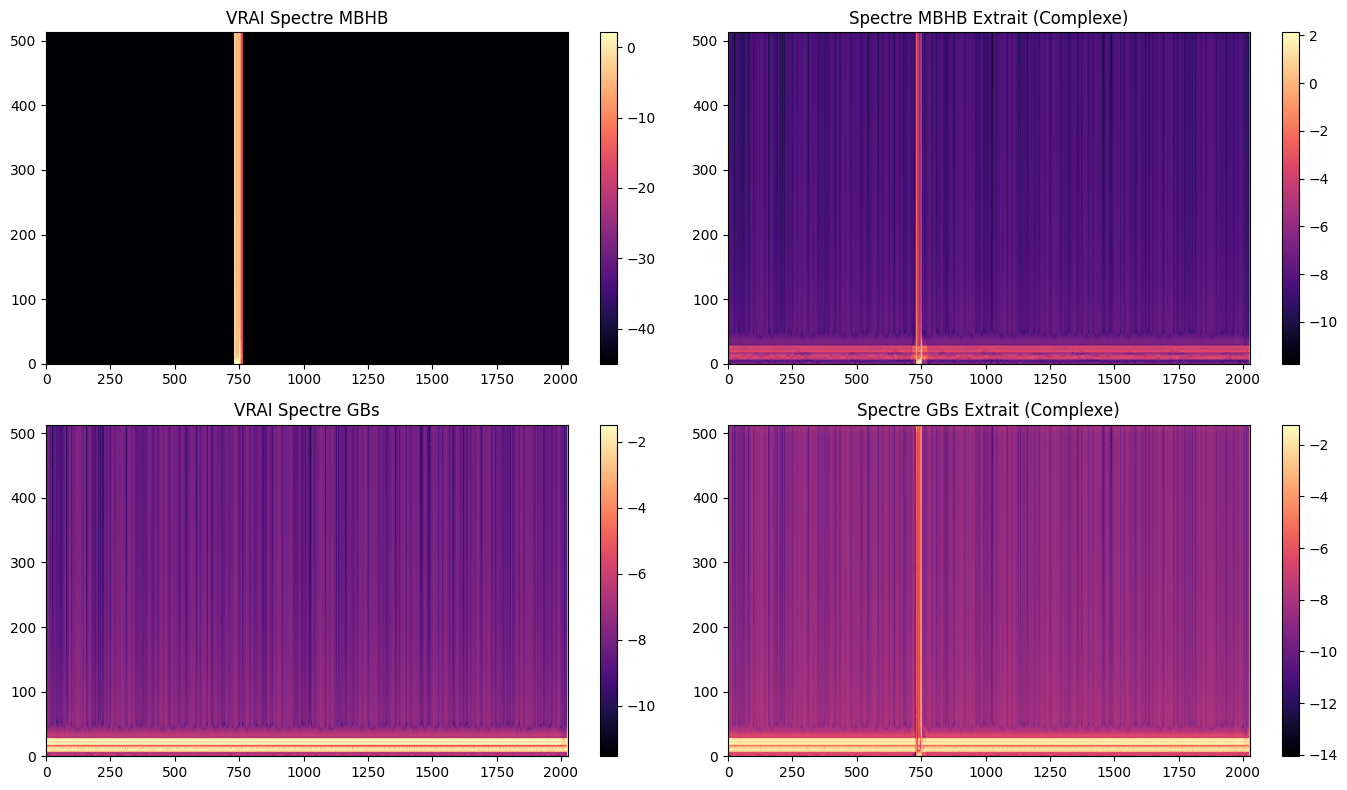

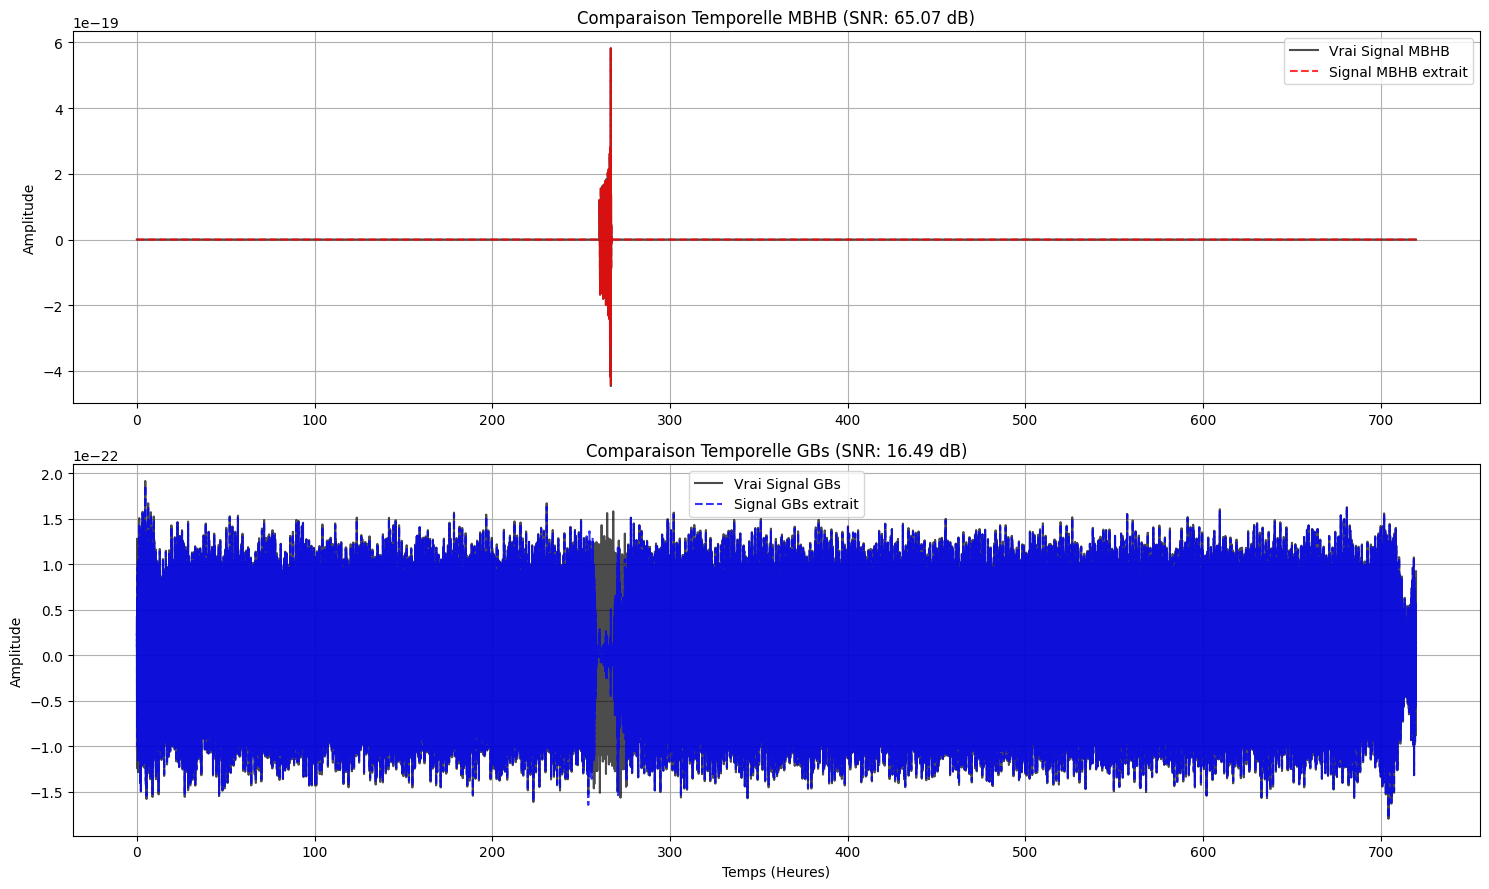

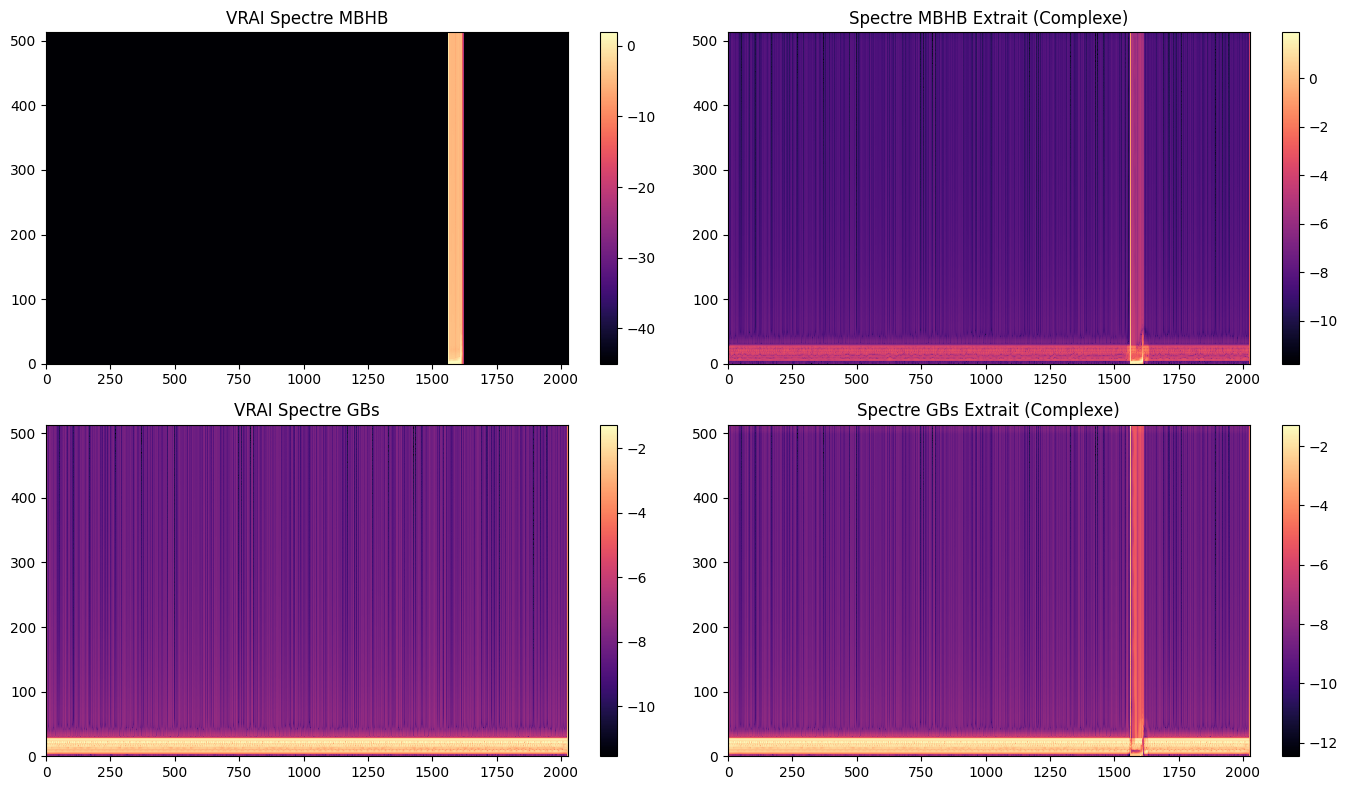

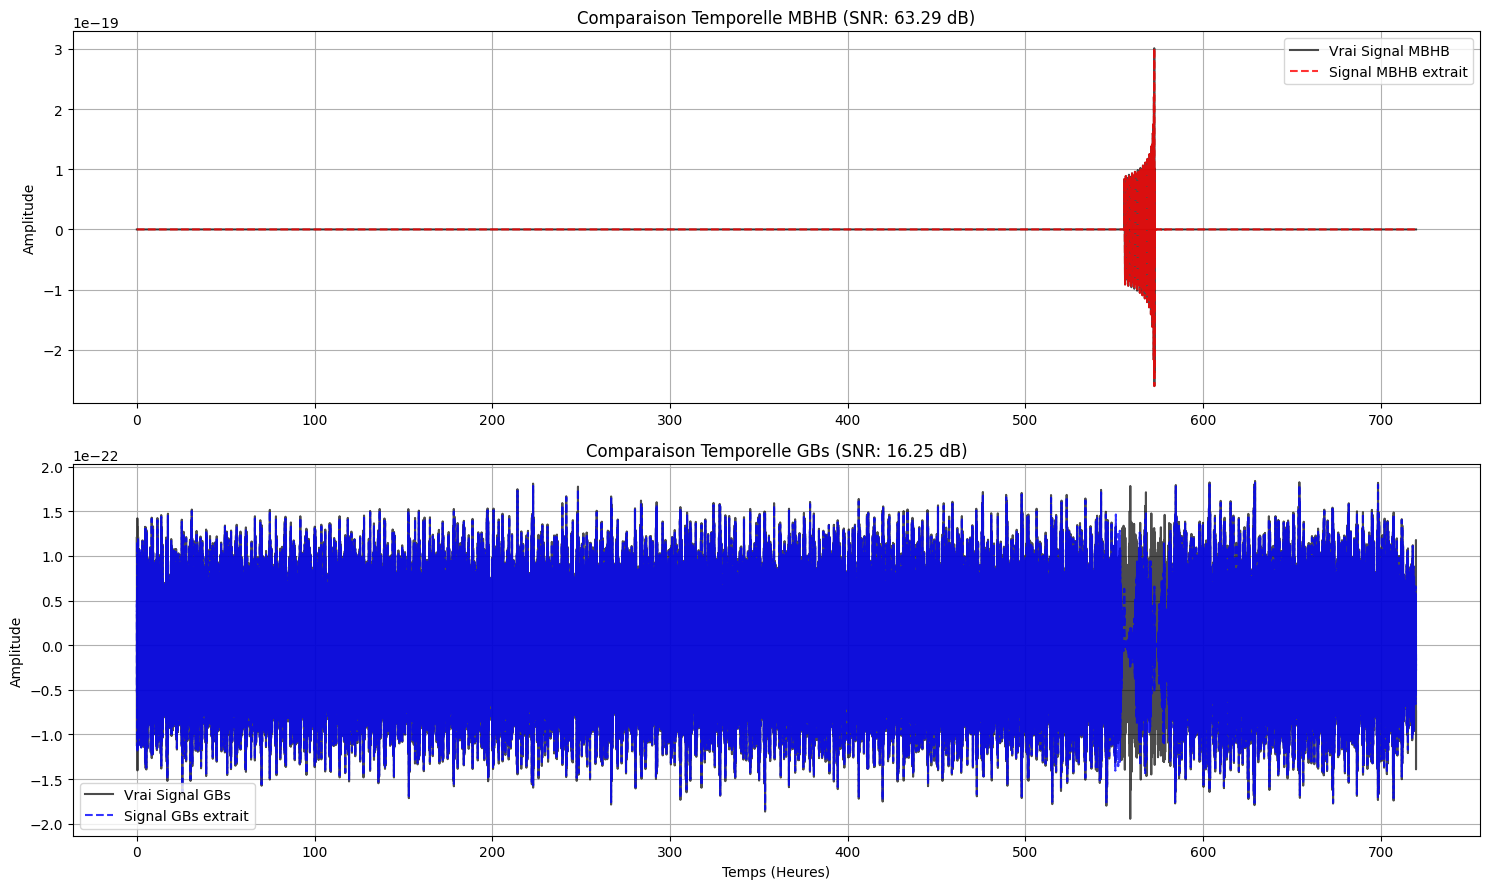

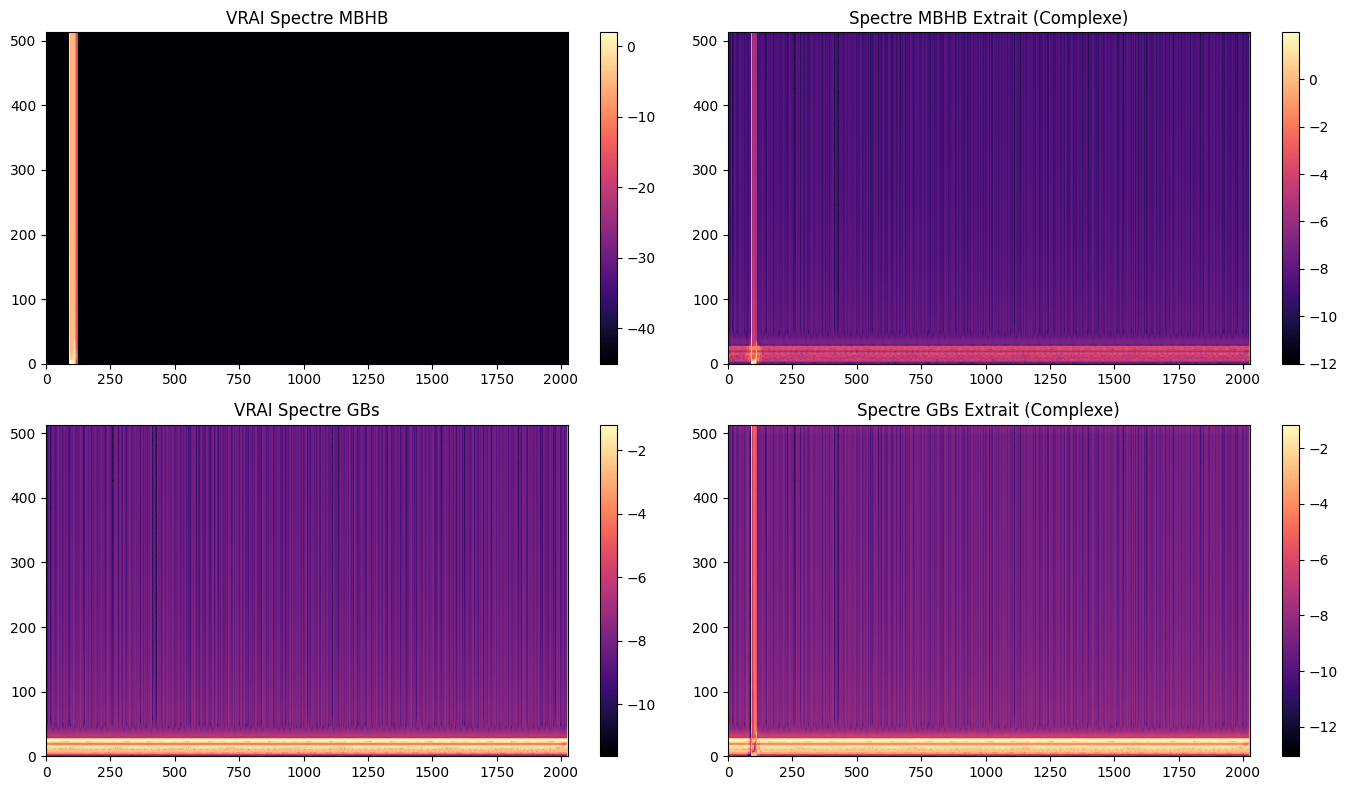

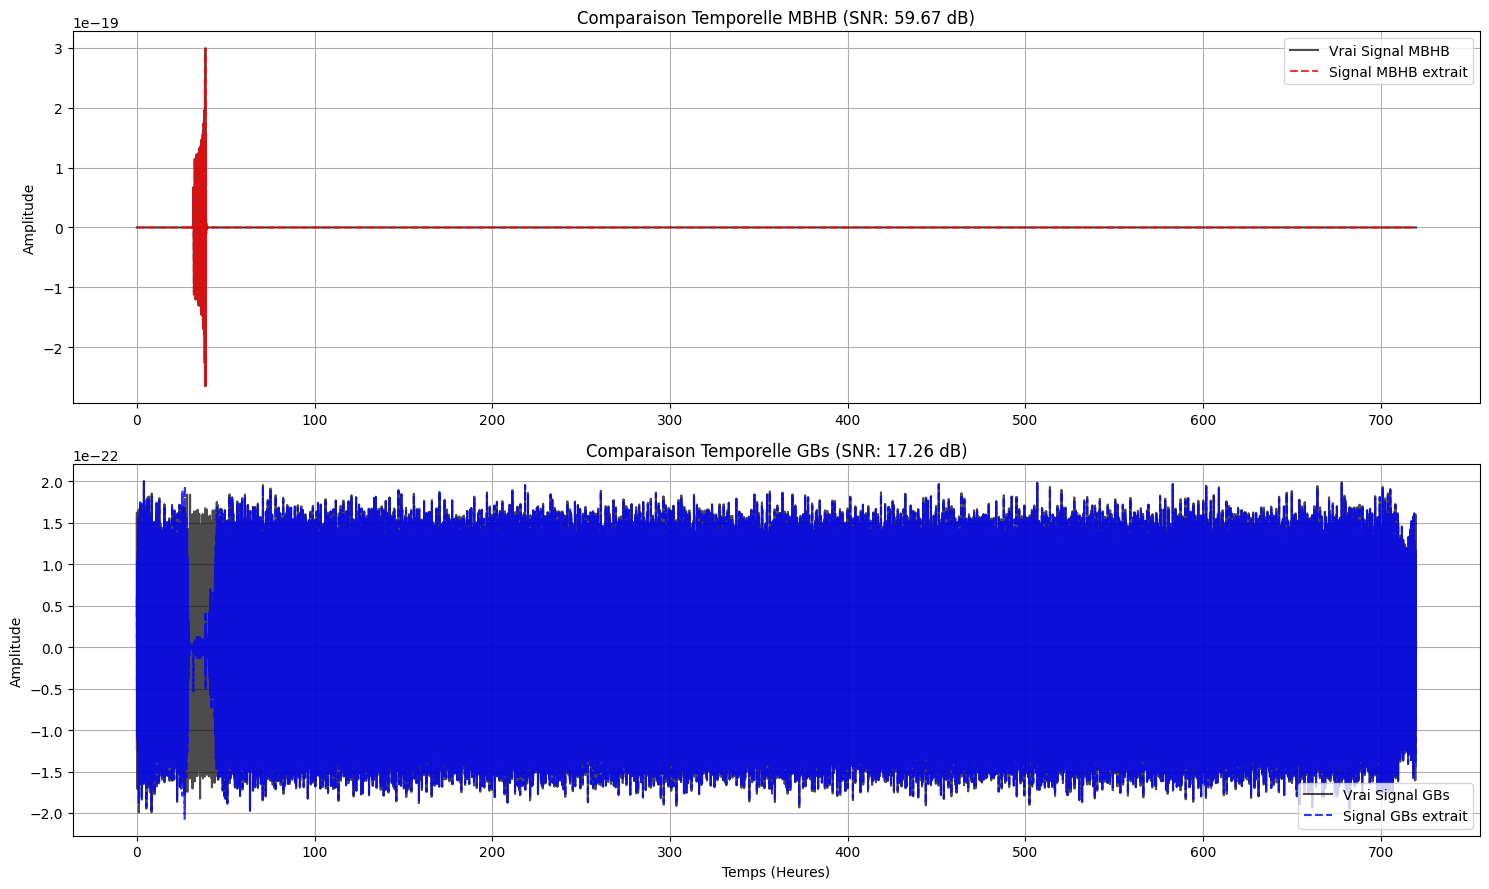

  RAPPORT DE SURVEILLANCE ROBUSTE : Complexe_Test_MSE
  Évalué sur 200 fenêtres indépendantes
Performances Temporelles Physiques réelles :
 - SNR Moyen MBHB : 63.13 dB (± 7.13)
 - SNR Moyen GBs  : 15.92 dB (± 2.99)


In [12]:
%matplotlib inline
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy import signal
import torch
import torch.nn as nn

# --- CHEMIN DES DONNÉES ---
DATA_DIR = r"C:\Stage LISA Mostafa\Data"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class LISAUNetComplexFilter(nn.Module):
    def __init__(self):
        super(LISAUNetComplexFilter, self).__init__()
        self.inc = DoubleConv(2, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up1 = DoubleConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_up2 = DoubleConv(32 + 16, 16)
        self.outc = nn.Conv2d(16, 4, kernel_size=1)

    def forward(self, x):
        orig_size = x.shape[2:]
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        up = self.up1(x3)
        up = nn.functional.interpolate(up, size=x2.shape[2:], mode='bilinear', align_corners=True)
        up = torch.cat([up, x2], dim=1)
        up = self.conv_up1(up)
        up = self.up2(up)
        up = nn.functional.interpolate(up, size=x1.shape[2:], mode='bilinear', align_corners=True)
        up = torch.cat([up, x1], dim=1)
        up = self.conv_up2(up)
        H = self.outc(up)
        H = nn.functional.interpolate(H, size=orig_size, mode='bilinear', align_corners=True)

        X_R, X_I = x[:, 0:1, :, :], x[:, 1:2, :, :]
        H_R_MBHB, H_I_MBHB = H[:, 0:1, :, :], H[:, 1:2, :, :]
        H_R_GB, H_I_GB   = H[:, 2:3, :, :], H[:, 3:4, :, :]

        S_R_MBHB = (H_R_MBHB * X_R) - (H_I_MBHB * X_I)
        S_I_MBHB = (H_R_MBHB * X_I) + (H_I_MBHB * X_R)
        S_R_GB = (H_R_GB * X_R) - (H_I_GB * X_I)
        S_I_GB = (H_R_GB * X_I) + (H_I_GB * X_R)

        return torch.cat([S_R_MBHB, S_I_MBHB, S_R_GB, S_I_GB], dim=1)

scale_factor = 1e21
dt = 5.0
FS = 1.0 / dt
nfft = 1024
nperseg, noverlap = nfft, nfft - (nfft // 4)
win_type = 'blackmanharris'

def compute_snr_robust(true, est):
    numerator = np.sum(true**2)
    residual = true - est
    denominator = np.sum(residual**2)
    if numerator == 0: return None
    if denominator == 0: return 100.0
    ratio = numerator / denominator
    if ratio <= 0: return -40.0
    return 10 * np.log10(ratio)

def evaluer_dataset_complexe(modele, chemin_h5, liste_indices, nom_experience):
    print(f"\n--- EVALUATION COMPLEXE : {nom_experience} ---")
    snr_mbhb_list = []
    snr_gbs_list = []
    
    with torch.no_grad():
        for idx_boucle, k in enumerate(liste_indices):
            with h5py.File(chemin_h5, 'r') as f:
                s1_true_phys = f['target'][k, 0, :].astype(np.float64)
                s2_true_phys = f['target'][k, 1, :].astype(np.float64)

            s1_scaled = s1_true_phys * scale_factor
            s2_scaled = s2_true_phys * scale_factor

            _, _, stft_s1 = signal.stft(s1_scaled, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, _, stft_s2 = signal.stft(s2_scaled, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            stft_mix = stft_s1 + stft_s2

            X = np.stack([np.real(stft_mix), np.imag(stft_mix)], axis=0)
            input_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(0).to(device)

            preds = modele(input_tensor)[0].cpu().numpy()
            
            stft_s1_est = preds[0] + 1j * preds[1]
            stft_s2_est = preds[2] + 1j * preds[3]

            _, s1_est_scaled = signal.istft(stft_s1_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)
            _, s2_est_scaled = signal.istft(stft_s2_est, fs=FS, window=win_type, nperseg=nperseg, noverlap=noverlap, nfft=nfft)

            min_len = min(len(s1_scaled), len(s1_est_scaled))
            s1_scaled, s1_est_scaled = s1_scaled[:min_len], s1_est_scaled[:min_len]
            s2_scaled, s2_est_scaled = s2_scaled[:min_len], s2_est_scaled[:min_len]

            snr_mbhb = compute_snr_robust(s1_scaled, s1_est_scaled)
            snr_gbs = compute_snr_robust(s2_scaled, s2_est_scaled)

            if snr_mbhb is not None: snr_mbhb_list.append(snr_mbhb)
            if snr_gbs is not None: snr_gbs_list.append(snr_gbs)

            s1_est_phys = s1_est_scaled / scale_factor
            s2_est_phys = s2_est_scaled / scale_factor
            s1_true_phys_aligned = s1_true_phys[:min_len]
            s2_true_phys_aligned = s2_true_phys[:min_len]

            if idx_boucle < 3:
                fig1, axs = plt.subplots(2, 2, figsize=(14, 8))
                im0 = axs[0, 0].pcolormesh(np.log10(np.abs(stft_s1) + 1e-45), cmap='magma'); axs[0, 0].set_title('VRAI Spectre MBHB'); fig1.colorbar(im0, ax=axs[0, 0])
                im1 = axs[0, 1].pcolormesh(np.log10(np.abs(stft_s1_est) + 1e-45), cmap='magma'); axs[0, 1].set_title('Spectre MBHB Extrait (Complexe)'); fig1.colorbar(im1, ax=axs[0, 1])
                im2 = axs[1, 0].pcolormesh(np.log10(np.abs(stft_s2) + 1e-45), cmap='magma'); axs[1, 0].set_title('VRAI Spectre GBs'); fig1.colorbar(im2, ax=axs[1, 0])
                im3 = axs[1, 1].pcolormesh(np.log10(np.abs(stft_s2_est) + 1e-45), cmap='magma'); axs[1, 1].set_title('Spectre GBs Extrait (Complexe)'); fig1.colorbar(im3, ax=axs[1, 1])
                plt.tight_layout()
                plt.show()

                step = 1 if min_len < 50000 else 10
                time_axis = np.arange(min_len) * dt / 3600.0
                fig2, axs2 = plt.subplots(2, 1, figsize=(15, 9))
                
                axs2[0].plot(time_axis[::step], s1_true_phys_aligned[::step], label='Vrai Signal MBHB', color='black', alpha=0.7)
                title_m = f'Comparaison Temporelle MBHB (SNR: {snr_mbhb:.2f} dB)' if snr_mbhb is not None else 'MBHB Absent'
                axs2[0].plot(time_axis[::step], s1_est_phys[::step], label='Signal MBHB extrait', color='red', linestyle='--', alpha=0.8)
                axs2[0].set_title(title_m); axs2[0].set_ylabel('Amplitude'); axs2[0].legend(); axs2[0].grid(True)

                axs2[1].plot(time_axis[::step], s2_true_phys_aligned[::step], label='Vrai Signal GBs', color='black', alpha=0.7)
                title_g = f'Comparaison Temporelle GBs (SNR: {snr_gbs:.2f} dB)' if snr_gbs is not None else 'GBs Absentes'
                axs2[1].plot(time_axis[::step], s2_est_phys[::step], label='Signal GBs extrait', color='blue', linestyle='--', alpha=0.8)
                axs2[1].set_title(title_g); axs2[1].set_xlabel('Temps (Heures)'); axs2[1].set_ylabel('Amplitude'); axs2[1].legend(); axs2[1].grid(True)
                
                plt.tight_layout()
                plt.show()

    mean_snr_mbhb, std_snr_mbhb = np.mean(snr_mbhb_list) if snr_mbhb_list else 0.0, np.std(snr_mbhb_list) if snr_mbhb_list else 0.0
    mean_snr_gbs, std_snr_gbs = np.mean(snr_gbs_list) if snr_gbs_list else 0.0, np.std(snr_gbs_list) if snr_gbs_list else 0.0

    rapport = [
        "=========================================================",
        f"  RAPPORT DE SURVEILLANCE ROBUSTE : {nom_experience}",
        f"  Évalué sur {len(liste_indices)} fenêtres indépendantes",
        "=========================================================",
        f"Performances Temporelles Physiques réelles :",
        f" - SNR Moyen MBHB : {mean_snr_mbhb:.2f} dB (± {std_snr_mbhb:.2f})",
        f" - SNR Moyen GBs  : {mean_snr_gbs:.2f} dB (± {std_snr_gbs:.2f})",
        "========================================================="
    ]
    for ligne in rapport: print(ligne)


if __name__ == "__main__":
    # Remplacer 'mse' par 'mae' ou 'both' pour comparer les trois modèles entrainés
    MODELE_PATH = os.path.join(DATA_DIR, 'lisa_unet_complexe_mse.pth')
    
    model = LISAUNetComplexFilter().to(device)
    model.load_state_dict(torch.load(MODELE_PATH, map_location=device, weights_only=True))
    model.eval()

    h5_initial = os.path.join(DATA_DIR, 'lisa_dataset_2k.h5')
    indices_test = list(range(1800, 2000))
    evaluer_dataset_complexe(model, h5_initial, indices_test, "Complexe_Test_MSE")


---
## Conclusion Générale et Comparaison des Méthodes

À travers les différentes implémentations codées et évaluées dans ce carnet Jupyter, nous avons pu identifier les forces et faiblesses des trois paradigmes pour l'isolation des MBHB et GBs de LISA :

1. **La Classification** segmente strictement les fréquences. Bien que visuellement nette sur les masques (`argmax`), elle entraine de lourdes pertes d'informations (clipping) aux points de croisement exacts entre la courbe de la masse binaire (MBHB) et les binaires galactiques (GBs), car la source la plus faible est artificiellement mise à zéro.

2. **La Régression** corrige ce défaut de clippage. Les masques souples gèrent le partage d'énergie. En revanche, l'algorithme utilise toujours l'information de **phase du mélange** lors de la reconstruction temporelle `istft`. Ceci limite drastiquement le rapport signal-sur-bruit (SNR) physique final.

3. **Le Filtrage Complexe (Masques Complexes)** représente l'approche la plus avancée en théorie pour ce problème. En prédisant des coefficients modifiables et applicables comme de véritables filtres inverses sur la composante Réelle ET Imaginaire, l'U-Net a la capacité de séparer l'amplitude et de corriger le déphasage. La comparaison des fonctions d'erreurs a démontré que :
   - Le modèle **MSE** pénalise très fortement les grands écarts (idéal pour reconstituer l'onde puissante des trous noirs supermassifs).
   - Le modèle **MAE** est très stable et tend à éradiquer totalement le plancher de bruit (idéal pour le nettoyage chirurgical des petites GBs de fond).
   - Le modèle **BOTH** (somme de MSE et MAE) offre un excellent compromis mathématique entre robustesse face aux pics et gestion du bruit continu.

**Bilan :** Théoriquement, le filtrage complexe est l'état de l'art. Cependant, sur notre jeu de données actuel, nos résultats quantitatifs montrent que c'est la **classification** qui a obtenu le meilleur SNR de reconstruction (72.13 dB pour la classification, contre 67.64 dB pour la régression et 63.13 dB pour le modèle complexe). Ce décalage entre la théorie et la pratique fait l'objet de notre analyse dans les limites de l'étude.

## 3. Limites rencontrées et perspectives

Bien que les approches par régression et par masques complexes soient théoriquement plus adaptées à la physique du problème (grâce à la gestion du partage d'énergie et de la phase), les résultats pratiques de nos tests montrent que **la méthode de classification obtient finalement les meilleures performances quantitatives**. 

Cette observation inattendue s'explique principalement par deux facteurs :
1. **La nature du jeu de données :** Il y a potentiellement un faible chevauchement effectif (et complexe) des signaux à séparer dans notre jeu de données synthétique actuel, rendant l'approche binaire de la classification suffisante et très performante pour extraire le signal fort.
2. **La difficulté d'optimisation :** L'entraînement d'un réseau de neurones sur des nombres complexes (ou pour prédire des masques continus très fins) est un problème d'optimisation beaucoup plus ardu. Il nécessite souvent des architectures plus profondes, des temps de convergence plus longs et un réglage d'hyperparamètres très délicat pour réussir à surpasser une classification "dure".

Un autre problème majeur rencontré au cours de l'étude concerne le masquage des signaux GBs lors des phases de début et de fin des événements MBHB. Cette difficulté découle de la différence extrême d'amplitude entre ces deux types de sources, et ce, malgré les méthodes de pondération mises en place pour équilibrer leur importance lors des calculs.

Par ailleurs, la durée limitée du stage, couplée aux temps d'entraînement très importants exigés par la grande longueur des signaux temporels, a restreint le nombre d'expérimentations possibles. Une phase de test plus exhaustive aurait été nécessaire pour optimiser pleinement les modèles complexes et révéler leur potentiel théorique.

Pour la suite de ce projet, les travaux futurs devront se concentrer sur l'amélioration de ces méthodes afin d'aboutir à une séparation optimale. Enfin, l'étape ultime et indispensable consistera à prendre en compte les bruits instrumentaux, volontairement ignorés lors de cette première phase d'étude, afin de se rapprocher des conditions réelles de la mission LISA.

---
## Cadre du stage et remerciements

Ce rapport documente les travaux de recherche et d'implémentation réalisés par **Ziad RAMMAL** dans le cadre de son stage au sein de l'**Institut de Recherche en Astrophysique et Planétologie (IRAP)**. 

Je tiens à exprimer ma profonde gratitude envers mes deux encadrants, **Mostafa BELLA** et **Shahram HOSSEINI**. Leurs précieux conseils, leur expertise scientifique et leur accompagnement m'ont été indispensables pour mener à bien cette étude sur le traitement des données de la mission spatiale LISA.